# Solar Power Prediction — Machine Learning Project

## Project Objective

The objective is to estimate solar inverter AC power (kW) using weather conditions and time-related features.

This project evaluates two different prediction tasks:

1. Weather-only prediction:
   Estimates same-interval AC power using weather and time features without previous AC-power readings.

2. Rolling Short-Term Nowcasting:
   Estimates current-interval AC power using current weather conditions and earlier measured AC-power readings from the same inverter.

Note: Rolling nowcasting is not a pure future forecast.

## Project Workflow

| Week | Activities |
|---|---|
| Week 1 | Problem understanding, EDA, preprocessing, baseline regression |
| Week 2 | Random Forest, XGBoost, hyperparameter tuning, cross-validation |
| Week 4 | Model selection, feature importance, business insights, limitations and deployment |

## Methodology

- Target variable: AC_POWER
- Problem type: Supervised Regression
- Train-test split: Chronological 70:30
- Evaluation metrics: MAE, RMSE and R²
- Validation: Time-aware cross-validation

Target-derived inverter-efficiency features are excluded from predictive modelling to prevent data leakage.

Rolling nowcasting features use only earlier inverter readings.

---
# WEEK 1 — Problem Understanding & Data Exploration

## 1.1 Business / scientific problem
Solar plants produce electricity that changes with sunlight, temperature and time of day. Grid operators and plant managers need to **forecast power output** to (a) balance supply and demand, (b) schedule maintenance and (c) detect under-performing equipment (inverters).

* **Problem type:** supervised **regression** (the target `AC_POWER` is continuous).
* **Target variable:** `AC_POWER` (AC power output of an inverter, in kW).
* **Why classification is not used:** the target is a continuous quantity, so classification algorithms/metrics (Logistic Regression, confusion matrix, ROC-AUC, SMOTE) are *not applicable* and no artificial classification task is created.

## 1.2 Dataset source (official)
**Solar Power Generation Data** — Kaggle dataset by *Ani Kannal* (`anikannal/solar-power-generation-data`), https://www.kaggle.com/datasets/anikannal/solar-power-generation-data.
The data were collected from **two solar power plants in India over 34 days at 15-minute intervals**. Each plant has two files:

| File | Content |
|---|---|
| `Plant_X_Generation_Data.csv` | one row per inverter per 15 min: `DC_POWER`, `AC_POWER`, `DAILY_YIELD`, `TOTAL_YIELD` |
| `Plant_X_Weather_Sensor_Data.csv` | one row per 15 min (plant-level sensor): `AMBIENT_TEMPERATURE`, `MODULE_TEMPERATURE`, `IRRADIATION` |

In [ ]:
!pip install -q xgboost python-docx kagglehub scipy

In [ ]:
# ---------------------------------------------------------------
# Imports, global settings and helper functions
# ---------------------------------------------------------------
import os, glob, json, random, textwrap, warnings, datetime
warnings.filterwarnings("ignore")

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Machine learning
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, TimeSeriesSplit, cross_validate
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import joblib

# Neural network (optional extra model). The notebook still runs if TensorFlow is missing.
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
    tf.random.set_seed(42)
    HAS_TF = True
    print("TensorFlow version:", tf.__version__)
except Exception as err:
    HAS_TF = False
    print("TensorFlow not available -> the optional Neural Network section will be skipped.", err)

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

sns.set_theme(style="whitegrid")

# Folder where every figure is stored (used later by the auto-generated reports)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    # Save the current matplotlib figure to figures/<name>.png and show it.
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()

def say(text, width=110):
    # Print a wrapped paragraph (used for the auto-generated interpretations).
    print(textwrap.fill(text, width=width))

print("All libraries imported successfully!")

TensorFlow version: 2.21.0
All libraries imported successfully!


In [ ]:
# ---------------------------------------------------------------
# Locate the dataset (Colab folder, Kaggle folder, local folder,
# or automatic download from the official Kaggle source)
# ---------------------------------------------------------------
REQUIRED_FILES = [
    "Plant_1_Generation_Data.csv",
    "Plant_1_Weather_Sensor_Data.csv",
    "Plant_2_Generation_Data.csv",
    "Plant_2_Weather_Sensor_Data.csv",
]
CANDIDATE_FOLDERS = [
    "/content/data", "/data", "data",
    "/kaggle/input/solar-power-generation-data", ".",
]

def find_data_folder():
    for folder in CANDIDATE_FOLDERS:
        if os.path.isdir(folder) and all(os.path.exists(os.path.join(folder, f)) for f in REQUIRED_FILES):
            return folder
    return None

DATA_PATH = find_data_folder()

if DATA_PATH is None:
    # Try the official source automatically (needs internet access)
    try:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub
        download_dir = kagglehub.dataset_download("anikannal/solar-power-generation-data")
        for root, _, files in os.walk(download_dir):
            if all(f in files for f in REQUIRED_FILES):
                DATA_PATH = root
                break
    except Exception as err:
        print("Automatic download was not possible:", err)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Download the 4 CSV files from "
        "https://www.kaggle.com/datasets/anikannal/solar-power-generation-data "
        "and upload them to /content/data (Colab: left sidebar -> Files -> upload)."
    )

print("Data folder location:", DATA_PATH)
print("\nFiles available:")
for file in sorted(os.listdir(DATA_PATH)):
    print(" -", file)

Using Colab cache for faster access to the 'solar-power-generation-data' dataset.
Data folder location: /kaggle/input/solar-power-generation-data

Files available:
 - Plant_1_Generation_Data.csv
 - Plant_1_Weather_Sensor_Data.csv
 - Plant_2_Generation_Data.csv
 - Plant_2_Weather_Sensor_Data.csv


In [ ]:
# Load the four CSV files
plant1_generation = pd.read_csv(os.path.join(DATA_PATH, "Plant_1_Generation_Data.csv"))
plant1_weather    = pd.read_csv(os.path.join(DATA_PATH, "Plant_1_Weather_Sensor_Data.csv"))
plant2_generation = pd.read_csv(os.path.join(DATA_PATH, "Plant_2_Generation_Data.csv"))
plant2_weather    = pd.read_csv(os.path.join(DATA_PATH, "Plant_2_Weather_Sensor_Data.csv"))

print("ALL FOUR DATASETS LOADED SUCCESSFULLY!")
print("\nPlant 1 Generation:", plant1_generation.shape)
print("Plant 1 Weather:   ", plant1_weather.shape)
print("Plant 2 Generation:", plant2_generation.shape)
print("Plant 2 Weather:   ", plant2_weather.shape)

ALL FOUR DATASETS LOADED SUCCESSFULLY!

Plant 1 Generation: (68778, 7)
Plant 1 Weather:    (3182, 6)
Plant 2 Generation: (67698, 7)
Plant 2 Weather:    (3259, 6)


In [ ]:
print("PLANT 1 GENERATION DATA")
display(plant1_generation.head())

print("\nPLANT 1 WEATHER DATA")
display(plant1_weather.head())

print("\nPLANT 2 GENERATION DATA")
display(plant2_generation.head())

print("\nPLANT 2 WEATHER DATA")
display(plant2_weather.head())

PLANT 1 GENERATION DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0



PLANT 1 WEATHER DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0



PLANT 2 GENERATION DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15 00:00:00,4136001,4UPUqMRk7TRMgml,0.0,0.0,9425.000000,2.429011e+06
1,2020-05-15 00:00:00,4136001,81aHJ1q11NBPMrL,0.0,0.0,0.000000,1.215279e+09
2,2020-05-15 00:00:00,4136001,9kRcWv60rDACzjR,0.0,0.0,3075.333333,2.247720e+09
3,2020-05-15 00:00:00,4136001,Et9kgGMDl729KT4,0.0,0.0,269.933333,1.704250e+06
4,2020-05-15 00:00:00,4136001,IQ2d7wF4YD8zU1Q,0.0,0.0,3177.000000,1.994153e+07



PLANT 2 WEATHER DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0
1,2020-05-15 00:15:00,4136001,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0
2,2020-05-15 00:30:00,4136001,iq8k7ZNt4Mwm3w0,26.682055,24.427290,0.0
3,2020-05-15 00:45:00,4136001,iq8k7ZNt4Mwm3w0,26.500589,24.420678,0.0
4,2020-05-15 01:00:00,4136001,iq8k7ZNt4Mwm3w0,26.596148,25.088210,0.0


In [ ]:
print("PLANT 1 GENERATION")
plant1_generation.info()

print("\nPLANT 1 WEATHER")
plant1_weather.info()

print("\nPLANT 2 GENERATION")
plant2_generation.info()

print("\nPLANT 2 WEATHER")
plant2_weather.info()

PLANT 1 GENERATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    68778 non-null  object 
 1   PLANT_ID     68778 non-null  int64  
 2   SOURCE_KEY   68778 non-null  object 
 3   DC_POWER     68778 non-null  float64
 4   AC_POWER     68778 non-null  float64
 5   DAILY_YIELD  68778 non-null  float64
 6   TOTAL_YIELD  68778 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 3.7+ MB

PLANT 1 WEATHER
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DATE_TIME            3182 non-null   object 
 1   PLANT_ID             3182 non-null   int64  
 2   SOURCE_KEY           3182 non-null   object 
 3   AMBIENT_TEMPERATURE  3182 non-null   float64
 4   MODUL

In [ ]:
# Convert DATE_TIME into datetime format (the two plants use different date formats)
for frame in (plant1_generation, plant1_weather, plant2_generation, plant2_weather):
    frame["DATE_TIME"] = pd.to_datetime(frame["DATE_TIME"], dayfirst=True)

# Weather: aggregate by timestamp and plant (one value per 15-minute slot)
weather_columns = ["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]

plant1_weather_clean = plant1_weather.groupby(["DATE_TIME", "PLANT_ID"], as_index=False)[weather_columns].mean()
plant2_weather_clean = plant2_weather.groupby(["DATE_TIME", "PLANT_ID"], as_index=False)[weather_columns].mean()

# Merge generation + weather for each plant
plant1 = pd.merge(plant1_generation, plant1_weather_clean, on=["DATE_TIME", "PLANT_ID"], how="inner", validate="many_to_one")
plant2 = pd.merge(plant2_generation, plant2_weather_clean, on=["DATE_TIME", "PLANT_ID"], how="inner", validate="many_to_one")

print("PLANT 1 MERGED SUCCESSFULLY:", plant1.shape)
print("PLANT 2 MERGED SUCCESSFULLY:", plant2.shape)
display(plant1.head())

PLANT 1 MERGED SUCCESSFULLY: (68774, 10)
PLANT 2 MERGED SUCCESSFULLY: (67698, 10)


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,25.184316,22.857507,0.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,25.184316,22.857507,0.0
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,25.184316,22.857507,0.0
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,25.184316,22.857507,0.0
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,25.184316,22.857507,0.0


In [ ]:
# Combine Plant 1 and Plant 2 and sort chronologically
data = pd.concat([plant1, plant2], ignore_index=True)
data = data.sort_values("DATE_TIME").reset_index(drop=True)

print("FINAL COMBINED DATASET")
print("Rows and columns:", data.shape)
display(data.head())

print("\nPlant distribution:")
print(data["PLANT_ID"].value_counts())

FINAL COMBINED DATASET
Rows and columns: (136472, 10)


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.000000,6.259559e+06,25.184316,22.857507,0.0
1,2020-05-15,4136001,Et9kgGMDl729KT4,0.0,0.0,269.933333,1.704250e+06,27.004764,25.060789,0.0
2,2020-05-15,4136001,IQ2d7wF4YD8zU1Q,0.0,0.0,3177.000000,1.994153e+07,27.004764,25.060789,0.0
3,2020-05-15,4136001,LYwnQax7tkwH5Cb,0.0,0.0,1872.500000,1.794959e+09,27.004764,25.060789,0.0
4,2020-05-15,4136001,LlT2YUhhzqhg5Sw,0.0,0.0,1094.357143,2.825928e+08,27.004764,25.060789,0.0



Plant distribution:
PLANT_ID
4135001    68774
4136001    67698
Name: count, dtype: int64


## 1.3 Dataset description — size, feature types and target variable

In [ ]:
# ---------------------------------------------------------------
# Dataset size, feature types and target variable
# ---------------------------------------------------------------
print("DATASET SIZE")
print("Rows    :", data.shape[0])
print("Columns :", data.shape[1])
print("Time span:", data["DATE_TIME"].min(), "->", data["DATE_TIME"].max(),
      f"({data['DATE_TIME'].dt.date.nunique()} days, 15-minute readings)")
print("Plants  :", sorted(data["PLANT_ID"].unique()))
print("Inverters (SOURCE_KEY):", data["SOURCE_KEY"].nunique())

feature_info = {
    "DATE_TIME":           ("Datetime (temporal)",            "Used to engineer time features",          "Timestamp of the 15-minute reading"),
    "PLANT_ID":            ("Categorical - nominal",          "Feature (encoded as PLANT_CODE)",         "Identifier of the solar plant (only 2 values)"),
    "SOURCE_KEY":          ("Categorical - identifier",       "Not a feature (used for inverter analysis)", "Inverter id (too many unique ids, no generalisation)"),
    "DC_POWER":            ("Numerical - continuous",         "Excluded (data leakage)",                 "DC input of the inverter; almost identical to the target"),
    "AC_POWER":            ("Numerical - continuous",         "TARGET",                                  "AC power output of the inverter (kW)"),
    "DAILY_YIELD":         ("Numerical - cumulative",         "Excluded (data leakage)",                 "Energy produced so far today; derived from power output"),
    "TOTAL_YIELD":         ("Numerical - cumulative",         "Excluded (data leakage)",                 "Lifetime energy of the inverter; derived from power output"),
    "AMBIENT_TEMPERATURE": ("Numerical - continuous",         "Feature",                                 "Air temperature near the plant (deg C)"),
    "MODULE_TEMPERATURE":  ("Numerical - continuous",         "Feature",                                 "Solar-panel temperature (deg C)"),
    "IRRADIATION":         ("Numerical - continuous",         "Feature",                                 "Solar irradiation reaching the panels (kW/m2)"),
}

feature_types = pd.DataFrame({
    "Column":       data.columns,
    "Data type":    [str(t) for t in data.dtypes],
    "Feature type": [feature_info.get(c, ("-", "-", "-"))[0] for c in data.columns],
    "Role":         [feature_info.get(c, ("-", "-", "-"))[1] for c in data.columns],
    "Description":  [feature_info.get(c, ("-", "-", "-"))[2] for c in data.columns],
})
print("\nFEATURE TYPES")
display(feature_types)

print("\nTARGET VARIABLE: AC_POWER")
display(data["AC_POWER"].describe().to_frame().T)
zero_share = (data["AC_POWER"] == 0).mean() * 100
print(f"Share of readings with AC_POWER = 0 (night / no sunlight / inverter off): {zero_share:.1f}%")

DATASET SIZE
Rows    : 136472
Columns : 10
Time span: 2020-05-15 00:00:00 -> 2020-06-17 23:45:00 (34 days, 15-minute readings)
Plants  : [np.int64(4135001), np.int64(4136001)]
Inverters (SOURCE_KEY): 44

FEATURE TYPES


,Column,Data type,Feature type,Role,Description
0,DATE_TIME,datetime64[ns],Datetime (temporal),Used to engineer time features,Timestamp of the 15-minute reading
1,PLANT_ID,int64,Categorical - nominal,Feature (encoded as PLANT_CODE),Identifier of the solar plant (only 2 values)
2,SOURCE_KEY,object,Categorical - identifier,Not a feature (used for inverter analysis),"Inverter id (too many unique ids, no generalis..."
3,DC_POWER,float64,Numerical - continuous,Excluded (data leakage),DC input of the inverter; almost identical to ...
4,AC_POWER,float64,Numerical - continuous,TARGET,AC power output of the inverter (kW)
5,DAILY_YIELD,float64,Numerical - cumulative,Excluded (data leakage),Energy produced so far today; derived from pow...
6,TOTAL_YIELD,float64,Numerical - cumulative,Excluded (data leakage),Lifetime energy of the inverter; derived from ...
7,AMBIENT_TEMPERATURE,float64,Numerical - continuous,Feature,Air temperature near the plant (deg C)
8,MODULE_TEMPERATURE,float64,Numerical - continuous,Feature,Solar-panel temperature (deg C)
9,IRRADIATION,float64,Numerical - continuous,Feature,Solar irradiation reaching the panels (kW/m2)



TARGET VARIABLE: AC_POWER


,count,mean,std,min,25%,50%,75%,max
AC_POWER,136472.0,274.790259,380.180214,0.0,0.0,3.493095,532.568571,1410.95


Share of readings with AC_POWER = 0 (night / no sunlight / inverter off): 49.5%


**Feature-type explanation**

* **Numerical continuous:** `AMBIENT_TEMPERATURE`, `MODULE_TEMPERATURE`, `IRRADIATION` (inputs) and `AC_POWER` (target). They are real-valued physical measurements.
* **Datetime:** `DATE_TIME` cannot be given to a model directly; it is converted to numerical calendar features (`HOUR`, `DAY`, `MONTH`, `DAY_OF_WEEK`, `DAY_OF_YEAR`) and a cyclical encoding (`HOUR_SIN`, `HOUR_COS`).
* **Categorical:** `PLANT_ID` is a *nominal* identifier (it only says *which* plant, the large numeric value has no order or magnitude), so it is encoded as `PLANT_CODE` (0/1). `SOURCE_KEY` (inverter id) has many unique values and would not generalise to new inverters, so it is kept only for the inverter-level business analysis.
* **Leakage columns:** `DC_POWER`, `DAILY_YIELD`, `TOTAL_YIELD` are *outputs of the same physical process as the target*. They are not available before the power is produced and would make the problem trivial, so they are **excluded** from the model inputs.

In [ ]:
# ---------------------------------------------------------------
# Missing value analysis
# ---------------------------------------------------------------
print("MISSING VALUE ANALYSIS")
missing = pd.DataFrame({
    "Missing values": data.isnull().sum(),
    "Missing %": (data.isnull().mean() * 100).round(3),
})
display(missing)
print("Total missing values:", int(data.isnull().sum().sum()))

MISSING VALUE ANALYSIS


,Missing values,Missing %
DATE_TIME,0,0.0
PLANT_ID,0,0.0
SOURCE_KEY,0,0.0
DC_POWER,0,0.0
AC_POWER,0,0.0
DAILY_YIELD,0,0.0
TOTAL_YIELD,0,0.0
AMBIENT_TEMPERATURE,0,0.0
MODULE_TEMPERATURE,0,0.0
IRRADIATION,0,0.0


Total missing values: 0


In [ ]:
# Check duplicate rows and remove them if present
duplicates = data.duplicated().sum()
print("Total duplicate records:", duplicates)

data = data.drop_duplicates().reset_index(drop=True)
print("Dataset shape after removing duplicates:", data.shape)

Total duplicate records: 0
Dataset shape after removing duplicates: (136472, 10)


**Missing-value interpretation.** The table above shows the number and percentage of missing values per column. The weather and generation files were merged with an *inner join* on `DATE_TIME` and `PLANT_ID`, so only timestamps present in both files are kept. If the table shows zero missing values, no imputation is required; otherwise the affected rows would be imputed or removed before modelling. Duplicate rows (if any) were removed.

In [ ]:
print("STATISTICAL DESCRIPTION")
display(data.describe())

STATISTICAL DESCRIPTION


,DATE_TIME,PLANT_ID,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,136472,1.364720e+05,136472.000000,136472.000000,136472.000000,1.364720e+05,136472.000000,136472.000000,136472.000000
mean,2020-06-01 09:22:57.605662720,4.135497e+06,1708.373962,274.790259,3295.366192,3.303916e+08,26.763066,31.920744,0.230767
min,2020-05-15 00:00:00,4.135001e+06,0.000000,0.000000,0.000000,0.000000e+00,20.398505,18.140415,0.000000
25%,2020-05-23 23:00:00,4.135001e+06,0.000000,0.000000,28.285714,6.520020e+06,23.637604,22.411698,0.000000
50%,2020-06-01 18:45:00,4.135001e+06,5.993333,3.493095,2834.642857,7.269333e+06,25.908122,26.413755,0.026213
75%,2020-06-09 21:45:00,4.136001e+06,1155.595000,532.568571,5992.000000,2.826096e+08,29.266583,40.778583,0.442961
max,2020-06-17 23:45:00,4.136001e+06,14471.125000,1410.950000,9873.000000,2.247916e+09,39.181638,66.635953,1.221652
std,NaN,4.999863e+02,3222.079306,380.180214,3035.313217,6.085769e+08,3.897340,11.803674,0.305652


## 1.4 Distribution analysis

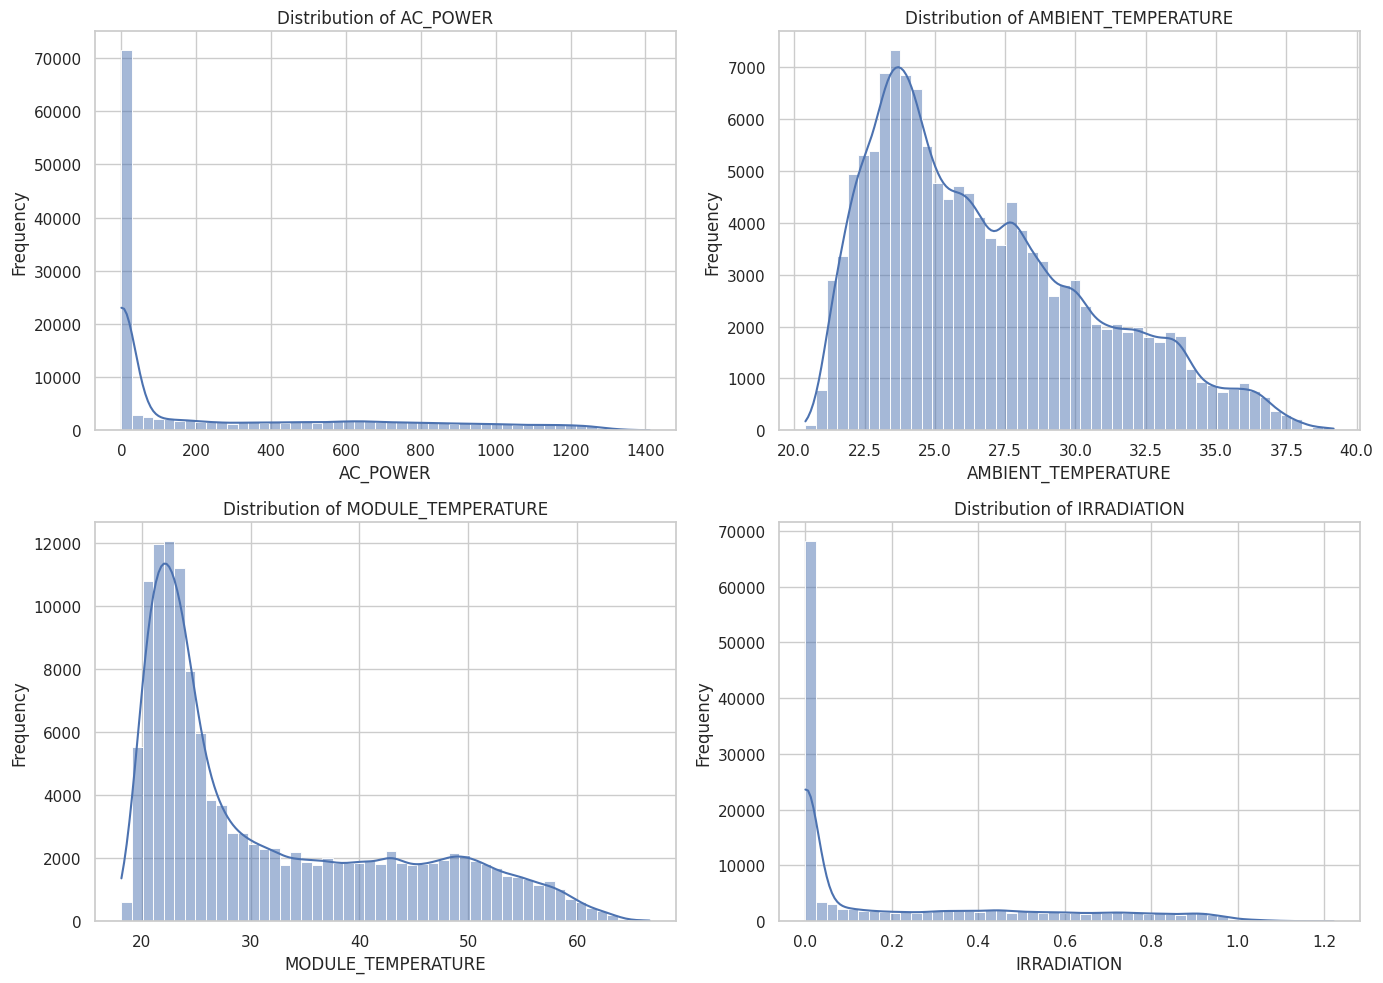

Skewness of each variable:
AC_POWER               1.15
AMBIENT_TEMPERATURE    0.73
MODULE_TEMPERATURE     0.88
IRRADIATION            1.06


In [ ]:
columns = ["AC_POWER", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]

plt.figure(figsize=(14, 10))
for i, col in enumerate(columns):
    plt.subplot(2, 2, i + 1)
    sns.histplot(data[col], bins=50, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
save_fig("01_distributions")

skew = data[columns].skew().round(2)
print("Skewness of each variable:")
print(skew.to_string())

**Interpretation (distributions).** `AC_POWER` and `IRRADIATION` are strongly **right-skewed with a large spike at/near zero**: solar plants produce nothing at night, so a large share of the readings are zero or very small (see the percentage printed in section 1.3), and high-output readings occur only around midday. The two temperature variables are broader and closer to bell-shaped, but have a second group of low values caused by night-time temperatures. Because of this skewness, models that do not assume normality (tree-based models) are expected to perform well; the skewness values printed above quantify the asymmetry.

## 1.5 Outlier detection

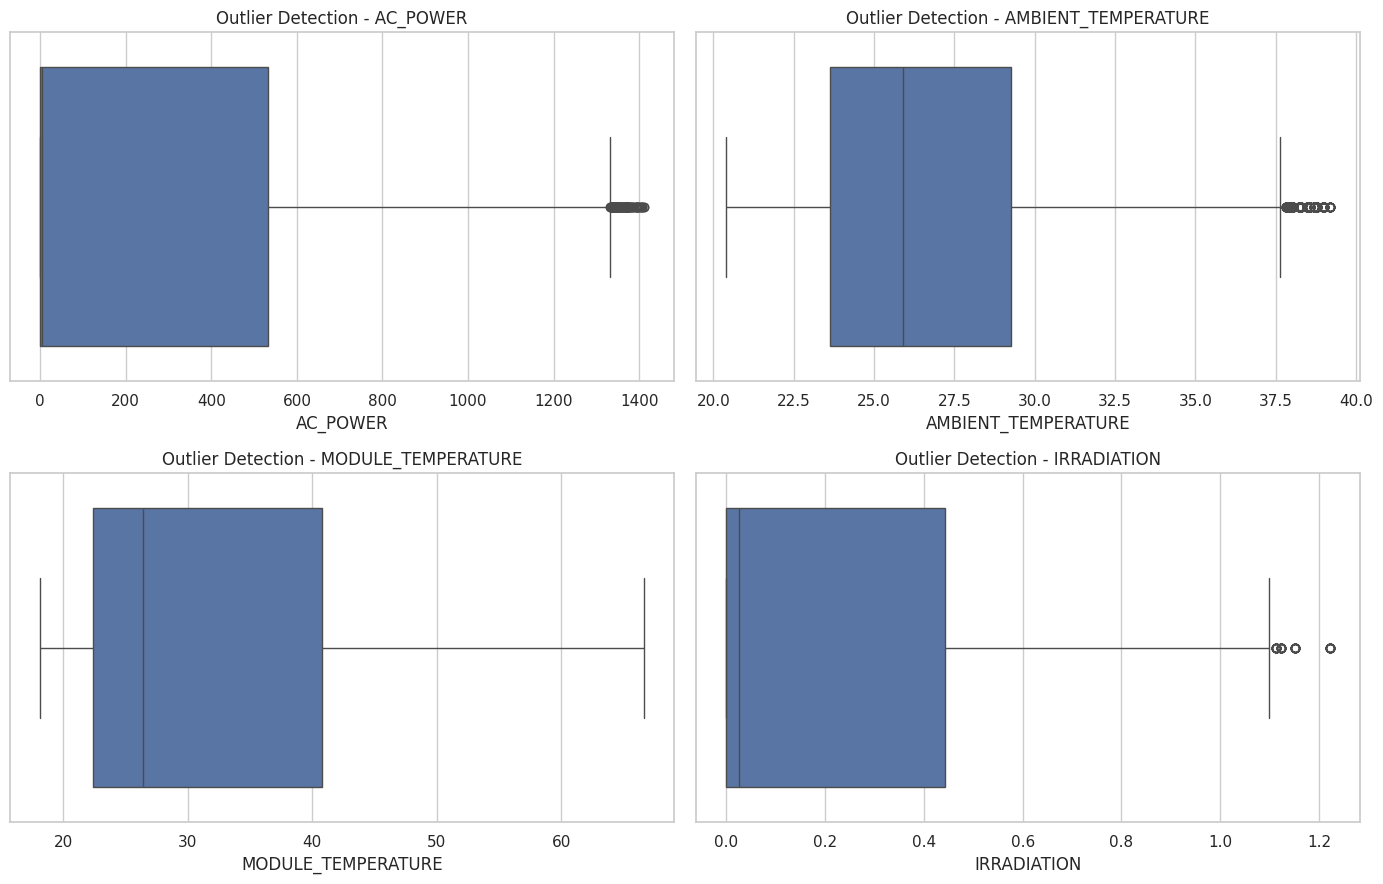

,Variable,Q1,Q3,Lower fence,Upper fence,Outliers,Outlier %
0,AC_POWER,0.000,532.569,-798.853,1331.421,126,0.09
1,AMBIENT_TEMPERATURE,23.638,29.267,15.194,37.710,378,0.28
2,MODULE_TEMPERATURE,22.412,40.779,-5.139,68.329,0,0.00
3,IRRADIATION,0.000,0.443,-0.664,1.107,88,0.06


In [ ]:
plt.figure(figsize=(14, 9))
for i, col in enumerate(columns):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x=data[col])
    plt.title(f"Outlier Detection - {col}")
save_fig("02_boxplots")

# Quantify the outliers with the IQR rule
outlier_rows = []
for col in columns:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((data[col] < low) | (data[col] > high)).sum())
    outlier_rows.append({
        "Variable": col, "Q1": round(q1, 3), "Q3": round(q3, 3),
        "Lower fence": round(low, 3), "Upper fence": round(high, 3),
        "Outliers": n_out, "Outlier %": round(100 * n_out / len(data), 2),
    })
outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table)

**Interpretation (outliers) and decision.** Values beyond the IQR fences (counts in the table above) are mainly high-production midday readings of `AC_POWER`/`IRRADIATION` or very hot module temperatures. These are **genuine physical values** (peak sunshine, hot afternoons), not sensor errors, and they are exactly the situations the model must predict well. Therefore the outliers are **kept** (no clipping/removal). Tree-based models are robust to them; for the distance-based and linear models, `StandardScaler` is applied inside a pipeline.

## 1.6 Correlation analysis

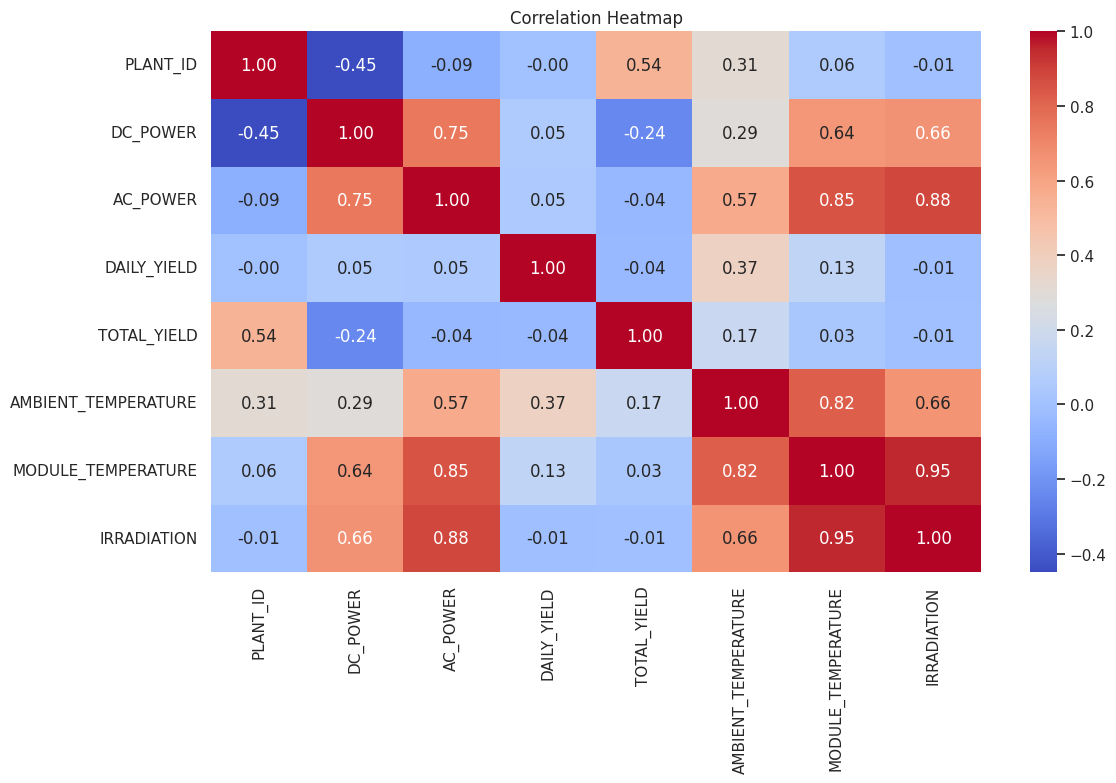

Correlation of every numerical column with AC_POWER:
IRRADIATION            0.885
MODULE_TEMPERATURE     0.852
DC_POWER               0.749
AMBIENT_TEMPERATURE    0.574
PLANT_ID              -0.087
DAILY_YIELD            0.047
TOTAL_YIELD           -0.044


In [ ]:
numeric_data = data.select_dtypes(include=np.number)
correlation = numeric_data.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
save_fig("03_correlation_heatmap")

corr_target = correlation["AC_POWER"].drop("AC_POWER").sort_values(key=np.abs, ascending=False)
print("Correlation of every numerical column with AC_POWER:")
print(corr_target.round(3).to_string())

In [ ]:
top_feat = corr_target.index[0]
weather_cols = ["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]
inter_corr = correlation.loc[weather_cols, weather_cols].values[np.triu_indices(3, 1)].min()
say(f"Interpretation (correlation): '{top_feat}' has the strongest linear relationship with AC_POWER "
    f"(r = {corr_target.iloc[0]:.3f}). Among the weather inputs, "
    f"IRRADIATION has r = {corr_target['IRRADIATION']:.3f}, MODULE_TEMPERATURE r = {corr_target['MODULE_TEMPERATURE']:.3f} "
    f"and AMBIENT_TEMPERATURE r = {corr_target['AMBIENT_TEMPERATURE']:.3f}. "
    f"DC_POWER (r = {corr_target['DC_POWER']:.3f}) is the inverter's DC input from which AC_POWER is produced (its correlation is reduced because DC and AC readings are on different scales in the two plants); "
    f"it is excluded as a data-leakage column because it is only known together with the output. "
    f"The weather inputs are also correlated with each other (lowest pairwise r = {inter_corr:.2f}); such multicollinearity is harmless for tree-based models "
    f"but can make the coefficients of Linear Regression unstable.")

Interpretation (correlation): 'IRRADIATION' has the strongest linear relationship with AC_POWER (r = 0.885).
Among the weather inputs, IRRADIATION has r = 0.885, MODULE_TEMPERATURE r = 0.852 and AMBIENT_TEMPERATURE r =
0.574. DC_POWER (r = 0.749) is the inverter's DC input from which AC_POWER is produced (its correlation is
reduced because DC and AC readings are on different scales in the two plants); it is excluded as a data-
leakage column because it is only known together with the output. The weather inputs are also correlated with
each other (lowest pairwise r = 0.66); such multicollinearity is harmless for tree-based models but can make
the coefficients of Linear Regression unstable.


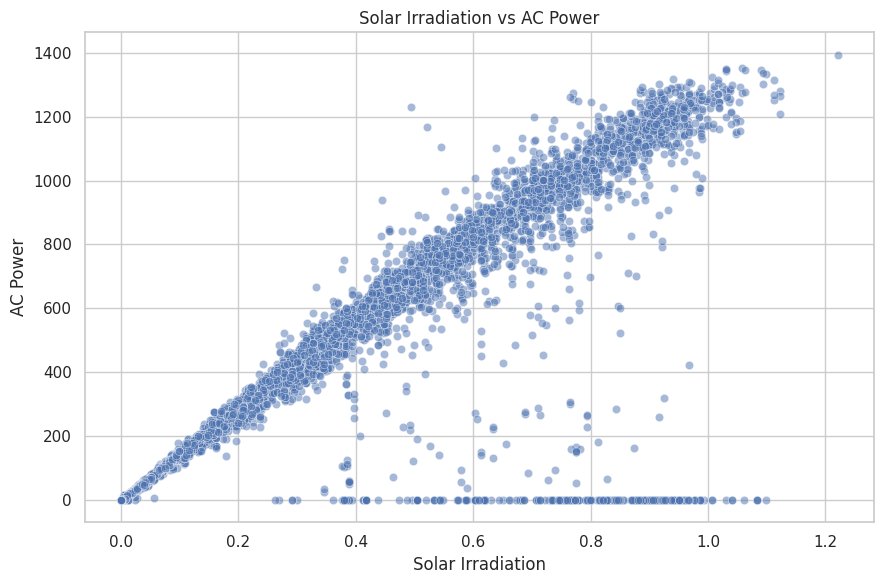

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=data.sample(min(10000, len(data)), random_state=SEED),
                x="IRRADIATION", y="AC_POWER", alpha=0.5)
plt.title("Solar Irradiation vs AC Power")
plt.xlabel("Solar Irradiation")
plt.ylabel("AC Power")
save_fig("04_irradiation_vs_power")

**Interpretation.** AC power rises almost linearly with irradiation: more sunlight means more electricity. The scatter around the main trend (including any points far below it) comes from inverters operating at reduced efficiency and from temperature effects, i.e. irradiation alone does not explain everything, which motivates using more features and non-linear models.

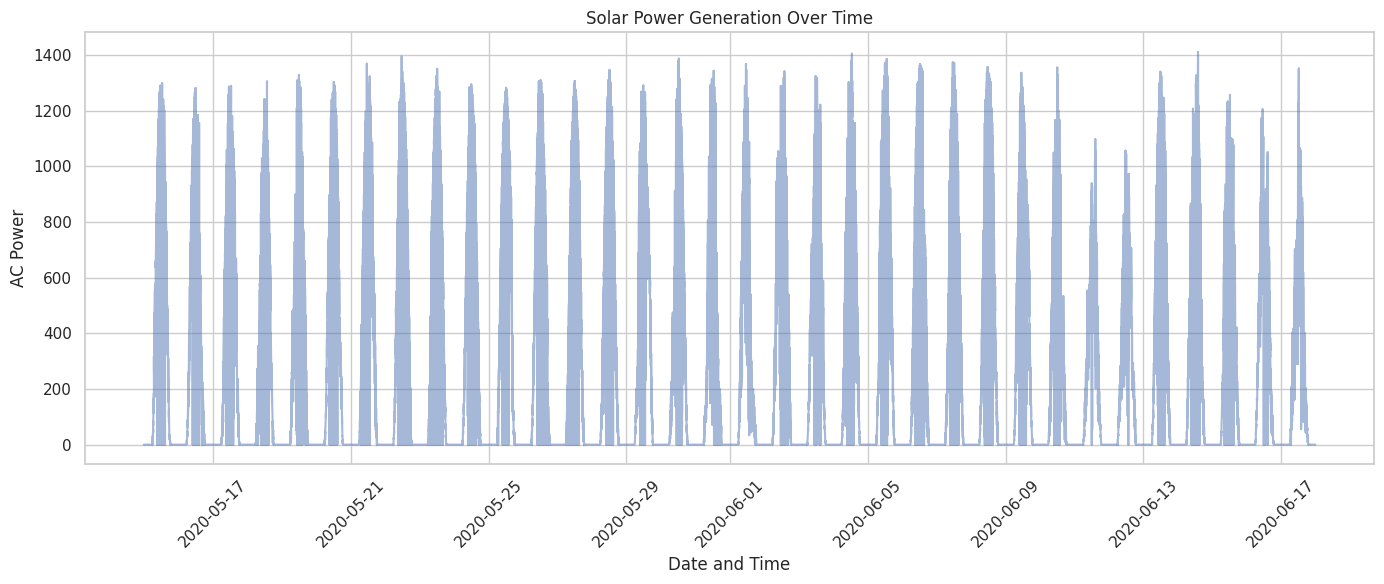

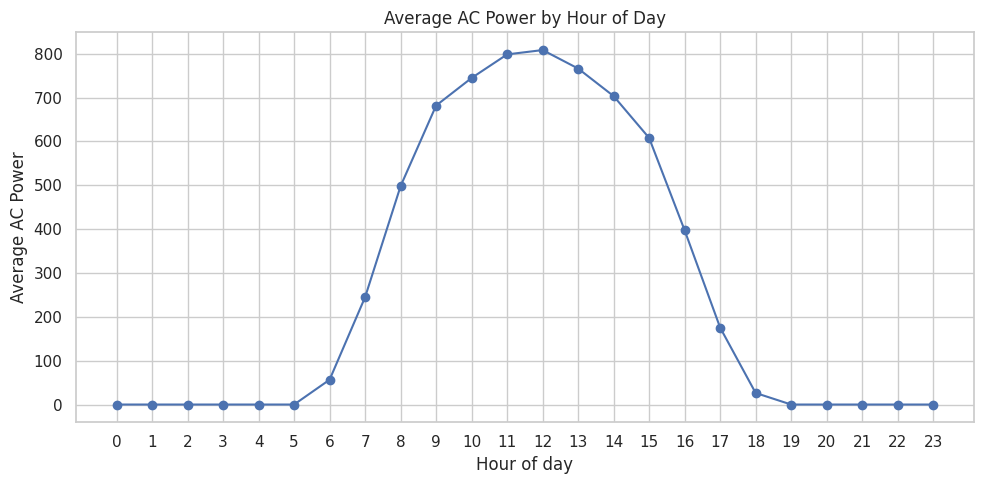

Interpretation (time pattern): generation follows a clear daily cycle - zero at night, rising after sunrise
and peaking around 12:00 (average 808.5 kW) before falling again. This strong daily seasonality is why hour-
of-day features are engineered below.


In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(data["DATE_TIME"], data["AC_POWER"], alpha=0.5)
plt.title("Solar Power Generation Over Time")
plt.xlabel("Date and Time")
plt.ylabel("AC Power")
plt.xticks(rotation=45)
save_fig("05_power_over_time")

# Average daily profile
hourly_profile = data.groupby(data["DATE_TIME"].dt.hour)["AC_POWER"].mean()
plt.figure(figsize=(10, 5))
hourly_profile.plot(marker="o")
plt.title("Average AC Power by Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("Average AC Power")
plt.xticks(range(0, 24))
save_fig("06_hourly_profile")

peak_hour = int(hourly_profile.idxmax())
say(f"Interpretation (time pattern): generation follows a clear daily cycle - zero at night, rising after sunrise and peaking around "
    f"{peak_hour}:00 (average {hourly_profile.max():.1f} kW) before falling again. This strong daily seasonality is why hour-of-day features are engineered below.")

## 1.7 Feature encoding
Models cannot use raw timestamps or a nominal plant identifier directly, so the following encodings are applied:

| Original | Encoding | Reason |
|---|---|---|
| `DATE_TIME` | `HOUR`, `DAY`, `MONTH`, `DAY_OF_WEEK`, `DAY_OF_YEAR` | numerical calendar information |
| `HOUR` | `HOUR_SIN`, `HOUR_COS` (cyclical encoding) | hour 23 and hour 0 are neighbours; sine/cosine keeps this circular distance |
| `PLANT_ID` (nominal, large numeric codes) | `PLANT_CODE` = 0 / 1 (label encoding) | with only **two** plants, a single 0/1 column is equivalent to one-hot encoding (no artificial order or magnitude) |

In [ ]:
# Time features
data["HOUR"] = data["DATE_TIME"].dt.hour
data["DAY"] = data["DATE_TIME"].dt.day
data["MONTH"] = data["DATE_TIME"].dt.month
data["DAY_OF_WEEK"] = data["DATE_TIME"].dt.dayofweek
data["DAY_OF_YEAR"] = data["DATE_TIME"].dt.dayofyear

# Cyclical hour encoding
data["HOUR_SIN"] = np.sin(2 * np.pi * data["HOUR"] / 24)
data["HOUR_COS"] = np.cos(2 * np.pi * data["HOUR"] / 24)

# Categorical encoding of PLANT_ID (binary 0/1 because there are exactly two plants)
plant_map = {pid: code for code, pid in enumerate(sorted(data["PLANT_ID"].unique()))}
data["PLANT_CODE"] = data["PLANT_ID"].map(plant_map).astype(int)

print("Feature engineering completed!")
print("PLANT_ID encoding used:", plant_map)
display(data.head())

Feature engineering completed!
PLANT_ID encoding used: {np.int64(4135001): 0, np.int64(4136001): 1}


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,HOUR,DAY,MONTH,DAY_OF_WEEK,DAY_OF_YEAR,HOUR_SIN,HOUR_COS,PLANT_CODE
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.000000,6.259559e+06,25.184316,22.857507,0.0,0,15,5,4,136,0.0,1.0,0
1,2020-05-15,4136001,Et9kgGMDl729KT4,0.0,0.0,269.933333,1.704250e+06,27.004764,25.060789,0.0,0,15,5,4,136,0.0,1.0,1
2,2020-05-15,4136001,IQ2d7wF4YD8zU1Q,0.0,0.0,3177.000000,1.994153e+07,27.004764,25.060789,0.0,0,15,5,4,136,0.0,1.0,1
3,2020-05-15,4136001,LYwnQax7tkwH5Cb,0.0,0.0,1872.500000,1.794959e+09,27.004764,25.060789,0.0,0,15,5,4,136,0.0,1.0,1
4,2020-05-15,4136001,LlT2YUhhzqhg5Sw,0.0,0.0,1094.357143,2.825928e+08,27.004764,25.060789,0.0,0,15,5,4,136,0.0,1.0,1


In [ ]:
# Independent variables
features = [
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION",
    "HOUR",
    "DAY",
    "MONTH",
    "DAY_OF_WEEK",
    "DAY_OF_YEAR",
    "HOUR_SIN",
    "HOUR_COS",
    "PLANT_CODE",
]

# Dependent variable
target = "AC_POWER"

X = data[features].copy()
y = data[target].copy()

print("FEATURES:", features)
print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in features:", int(X.isnull().sum().sum()))
print("Missing values in target  :", int(y.isnull().sum()))
print("Infinite values           :", int(np.isinf(X.select_dtypes(include=np.number)).sum().sum()))
display(X.head())

FEATURES: ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'HOUR', 'DAY', 'MONTH', 'DAY_OF_WEEK', 'DAY_OF_YEAR', 'HOUR_SIN', 'HOUR_COS', 'PLANT_CODE']

Input shape: (136472, 11)
Target shape: (136472,)

Missing values in features: 0
Missing values in target  : 0
Infinite values           : 0


,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,HOUR,DAY,MONTH,DAY_OF_WEEK,DAY_OF_YEAR,HOUR_SIN,HOUR_COS,PLANT_CODE
0,25.184316,22.857507,0.0,0,15,5,4,136,0.0,1.0,0
1,27.004764,25.060789,0.0,0,15,5,4,136,0.0,1.0,1
2,27.004764,25.060789,0.0,0,15,5,4,136,0.0,1.0,1
3,27.004764,25.060789,0.0,0,15,5,4,136,0.0,1.0,1
4,27.004764,25.060789,0.0,0,15,5,4,136,0.0,1.0,1


## 1.8 Train-test split (70 : 30)
The data is a **time series**, so a random split would leak future information into the training set. A **chronological** split is used: the first 70 % of the timeline is the training set and the last 30 % is the test set. The cut is made **between timestamps** (all inverter readings of one timestamp belong to the same set), so the proportions are 70:30 up to a few rows.

In [ ]:
# Ensure chronological order, then split 70 : 30
data = data.sort_values("DATE_TIME").reset_index(drop=True)

X = data[features]
y = data[target]

split_index = int(len(data) * 0.70)
# Move the cut to a timestamp boundary: every reading of one timestamp must belong to ONE set only
cutoff_time = data["DATE_TIME"].iloc[split_index]
split_index = int((data["DATE_TIME"] < cutoff_time).sum())
assert data["DATE_TIME"].iloc[split_index - 1] < data["DATE_TIME"].iloc[split_index], "a timestamp is split between train and test"

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print("Training samples:", X_train.shape)
print("Testing samples :", X_test.shape)
print("Training percentage:", round(len(X_train) / len(data) * 100, 2))
print("Testing percentage :", round(len(X_test) / len(data) * 100, 2))
print("\nCut made between timestamps - no timestamp appears in both sets.")
print("Train period:", data['DATE_TIME'].iloc[0], "->", data['DATE_TIME'].iloc[split_index - 1])
print("Test period :", data['DATE_TIME'].iloc[split_index], "->", data['DATE_TIME'].iloc[-1])

Training samples: (95508, 11)
Testing samples : (40964, 11)
Training percentage: 69.98
Testing percentage : 30.02

Cut made between timestamps - no timestamp appears in both sets.
Train period: 2020-05-15 00:00:00 -> 2020-06-08 06:45:00
Test period : 2020-06-08 07:00:00 -> 2020-06-17 23:45:00


---
# WEEK 1 — Baseline Modeling (Regression)

Required regression baselines: **Linear Regression, Decision Tree Regressor, KNN Regressor**.
Metrics: **MAE, RMSE, R²**. *All three baselines are evaluated on exactly the same (full) test set.*

> Classification models (Logistic Regression, classification Decision Tree/KNN) and classification metrics (accuracy, precision, recall, F1, confusion matrix) are **not applicable** because `AC_POWER` is a continuous target.

In [ ]:
# Containers that store the results of every model (re-running a cell simply overwrites the entry)
results = {}      # model name -> metrics
predictions = {}  # model name -> test-set predictions
models = {}       # model name -> fitted model

def evaluate_model(name, actual, predicted, verbose=True):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    results[name] = {"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2}
    predictions[name] = predicted
    if verbose:
        print(name)
        print("  MAE      :", round(mae, 4))
        print("  RMSE     :", round(rmse, 4))
        print("  R2 Score :", round(r2, 4))
        print("-" * 40)

def results_table(names=None):
    table = pd.DataFrame(list(results.values()))
    if names is not None:
        table = table[table["Model"].isin(names)]
    return table.sort_values("RMSE").reset_index(drop=True)

# 1) Linear Regression (scaling inside a pipeline)
lr_model = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
lr_model.fit(X_train, y_train)
models["Linear Regression"] = lr_model
evaluate_model("Linear Regression", y_test, lr_model.predict(X_test))

Linear Regression
  MAE      : 79.6653
  RMSE     : 151.7007
  R2 Score : 0.8081
----------------------------------------


In [ ]:
# 2) Decision Tree Regressor
dt_model = DecisionTreeRegressor(max_depth=15, min_samples_split=10, random_state=SEED)
dt_model.fit(X_train, y_train)
models["Decision Tree"] = dt_model
evaluate_model("Decision Tree", y_test, dt_model.predict(X_test))

Decision Tree
  MAE      : 50.9805
  RMSE     : 139.3816
  R2 Score : 0.838
----------------------------------------


In [ ]:
# 3) KNN Regressor - trained on the full training set and evaluated on the SAME full test set as every other model
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=5, n_jobs=-1)),
])
knn_model.fit(X_train, y_train)
models["KNN Regressor"] = knn_model
evaluate_model("KNN Regressor", y_test, knn_model.predict(X_test))

KNN Regressor
  MAE      : 71.8024
  RMSE     : 162.2188
  R2 Score : 0.7806
----------------------------------------


In [ ]:
BASELINE_MODELS = ["Linear Regression", "Decision Tree", "KNN Regressor"]

# Safety net: if a baseline cell was skipped (or `results` was reset by re-running an earlier cell),
# the missing baseline models are trained again here so that nothing below can fail.
baseline_factories = {
    "Linear Regression": lambda: Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
    "Decision Tree": lambda: DecisionTreeRegressor(max_depth=15, min_samples_split=10, random_state=SEED),
    "KNN Regressor": lambda: Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=5, n_jobs=-1))]),
}
for _name, _make in baseline_factories.items():
    if _name not in results:
        print(f"'{_name}' was missing - training it now...")
        _m = _make().fit(X_train, y_train)
        models[_name] = _m
        evaluate_model(_name, y_test, _m.predict(X_test), verbose=False)
    elif _name not in models:
        models[_name] = _make().fit(X_train, y_train)

baseline_results = results_table(BASELINE_MODELS)
print("BASELINE MODEL COMPARISON TABLE (same test set: {} samples)".format(len(y_test)))
display(baseline_results)

# Auto-generated interpretation paragraph (always matches the numbers above)
best_b, worst_b = baseline_results.iloc[0], baseline_results.iloc[-1]
lr_r, dt_r = results["Linear Regression"], results["Decision Tree"]
if dt_r["RMSE"] < lr_r["RMSE"]:
    nonlin = (f"The non-linear Decision Tree (RMSE {dt_r['RMSE']:.2f}) beat the linear model (RMSE {lr_r['RMSE']:.2f}), which shows that the relationship between "
              f"weather, time of day and power is not purely linear.")
else:
    nonlin = (f"The linear model (RMSE {lr_r['RMSE']:.2f}) was at least as good as the single Decision Tree (RMSE {dt_r['RMSE']:.2f}), which shows that the relationship between "
              f"irradiation and power is largely linear and that a single deep tree tends to over-fit.")
baseline_interpretation = (
    f"Among the baseline models, {best_b['Model']} performed best with RMSE = {best_b['RMSE']:.2f}, MAE = {best_b['MAE']:.2f} and R2 = {best_b['R2 Score']:.4f}, "
    f"while {worst_b['Model']} was the weakest (RMSE = {worst_b['RMSE']:.2f}, R2 = {worst_b['R2 Score']:.4f}). {nonlin} "
    f"KNN depends on distances between scaled features and is slow at prediction time. "
    f"MAE is in kW and RMSE penalises large errors more strongly, so a large gap between them indicates a few big mistakes. "
    f"These baselines set the reference performance that the advanced models of Week 2 have to beat.")
say("Interpretation: " + baseline_interpretation)

BASELINE MODEL COMPARISON TABLE (same test set: 40964 samples)


,Model,MAE,RMSE,R2 Score
0,Decision Tree,50.980470,139.381633,0.837995
1,Linear Regression,79.665348,151.700741,0.808092
2,KNN Regressor,71.802428,162.218773,0.780558


Interpretation: Among the baseline models, Decision Tree performed best with RMSE = 139.38, MAE = 50.98 and R2
= 0.8380, while KNN Regressor was the weakest (RMSE = 162.22, R2 = 0.7806). The non-linear Decision Tree (RMSE
139.38) beat the linear model (RMSE 151.70), which shows that the relationship between weather, time of day
and power is not purely linear. KNN depends on distances between scaled features and is slow at prediction
time. MAE is in kW and RMSE penalises large errors more strongly, so a large gap between them indicates a few
big mistakes. These baselines set the reference performance that the advanced models of Week 2 have to beat.


---
# WEEK 2 — Advanced Modeling & Optimization

* **Random Forest** and **XGBoost** (gradient boosting)
* **Hyper-parameter tuning:** `RandomizedSearchCV` (broad exploration) followed by an actual **`GridSearchCV`** (focused refinement)
* **Cross-validation:** `TimeSeriesSplit` (3 folds, training data always precedes validation data)
* **Regression-specific analysis:** residual analysis and feature importance

(ROC curve, AUC and SMOTE/class weights are classification-only techniques and are not applicable here.)

In [ ]:
class TimestampTimeSeriesSplit:
    # Expanding-window time-series cross-validation that cuts ONLY between timestamps
    # (like TimeSeriesSplit, but no timestamp is shared by a training and a validation part).
    def __init__(self, n_splits=3):
        self.n_splits = n_splits
    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits
    def split(self, X, y=None, groups=None):
        n = len(X)                                   # X is always the first n (training) rows of `data`
        dates = data["DATE_TIME"].values[:n]
        unique_dates, first_pos = np.unique(dates, return_index=True)
        step = len(unique_dates) // (self.n_splits + 1)
        for k in range(1, self.n_splits + 1):
            train_end = int(first_pos[step * k])
            val_end = int(first_pos[step * (k + 1)]) if step * (k + 1) < len(unique_dates) else n
            yield np.arange(0, train_end), np.arange(train_end, val_end)

tscv = TimestampTimeSeriesSplit(n_splits=3)
tuning_summary = []   # collects best parameters and best CV RMSE of every search

# ---- Random Forest: RandomizedSearchCV ----
rf = RandomForestRegressor(random_state=SEED, n_jobs=-1)

rf_parameters = {
    "n_estimators": [100, 150],
    "max_depth": [10, 15, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

rf_search = RandomizedSearchCV(
    estimator=rf, param_distributions=rf_parameters, n_iter=6, cv=tscv,
    scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=1, verbose=1,
)
rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
models["Tuned Random Forest"] = best_rf
print("Best Random Forest Parameters:", rf_search.best_params_)
print("Best CV RMSE:", round(-rf_search.best_score_, 4))
tuning_summary.append({"Model": "Random Forest", "Method": "RandomizedSearchCV",
                       "Best parameters": str(rf_search.best_params_), "CV RMSE": -rf_search.best_score_})

evaluate_model("Tuned Random Forest", y_test, best_rf.predict(X_test))

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Random Forest Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 10}
Best CV RMSE: 177.1684
Tuned Random Forest
  MAE      : 49.6111
  RMSE     : 137.8281
  R2 Score : 0.8416
----------------------------------------


In [ ]:
# ---- XGBoost: RandomizedSearchCV ----
xgb = XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=-1, tree_method="hist")

xgb_parameters = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

xgb_search = RandomizedSearchCV(
    estimator=xgb, param_distributions=xgb_parameters, n_iter=8, cv=tscv,
    scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=1, verbose=1,
)
xgb_search.fit(X_train, y_train)

xgb_random_best = xgb_search.best_estimator_
models["Tuned XGBoost (RandomizedSearchCV)"] = xgb_random_best
print("Best XGBoost Parameters (random search):", xgb_search.best_params_)
print("Best CV RMSE:", round(-xgb_search.best_score_, 4))
tuning_summary.append({"Model": "XGBoost", "Method": "RandomizedSearchCV",
                       "Best parameters": str(xgb_search.best_params_), "CV RMSE": -xgb_search.best_score_})

evaluate_model("Tuned XGBoost (RandomizedSearchCV)", y_test, xgb_random_best.predict(X_test))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best XGBoost Parameters (random search): {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Best CV RMSE: 168.157
Tuned XGBoost (RandomizedSearchCV)
  MAE      : 52.7177
  RMSE     : 133.0732
  R2 Score : 0.8523
----------------------------------------


### GridSearchCV experiments
`RandomizedSearchCV` explores the parameter space broadly; `GridSearchCV` then evaluates **every** combination of a smaller grid.
For XGBoost the grid is built *around the best random-search result* (a standard coarse-to-fine tuning strategy); for the Decision Tree an exhaustive grid is used. Both use the same time-series cross-validation.

In [ ]:
# ---- XGBoost: GridSearchCV (fine search around the random-search optimum) ----
bp = xgb_search.best_params_

xgb_grid_parameters = {
    "max_depth": sorted({max(2, bp["max_depth"] - 1), bp["max_depth"], bp["max_depth"] + 1}),
    "learning_rate": sorted({bp["learning_rate"], round(bp["learning_rate"] * 2, 3)}),
    "n_estimators": sorted({bp["n_estimators"], bp["n_estimators"] + 100}),
    "subsample": [bp["subsample"]],
    "colsample_bytree": [bp["colsample_bytree"]],
}
print("XGBoost GridSearchCV grid:", xgb_grid_parameters)

xgb_grid = GridSearchCV(
    estimator=XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=-1, tree_method="hist"),
    param_grid=xgb_grid_parameters, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=1, verbose=1,
)
xgb_grid.fit(X_train, y_train)

print("\nBest XGBoost Parameters (GridSearchCV):", xgb_grid.best_params_)
print("Best CV RMSE:", round(-xgb_grid.best_score_, 4))
tuning_summary.append({"Model": "XGBoost", "Method": "GridSearchCV",
                       "Best parameters": str(xgb_grid.best_params_), "CV RMSE": -xgb_grid.best_score_})

models["Tuned XGBoost (GridSearchCV)"] = xgb_grid.best_estimator_
evaluate_model("Tuned XGBoost (GridSearchCV)", y_test, xgb_grid.best_estimator_.predict(X_test))

XGBoost GridSearchCV grid: {'max_depth': [2, 3, 4], 'learning_rate': [0.03, 0.06], 'n_estimators': [300, 400], 'subsample': [0.8], 'colsample_bytree': [0.8]}
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best XGBoost Parameters (GridSearchCV): {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 400, 'subsample': 0.8}
Best CV RMSE: 165.7725
Tuned XGBoost (GridSearchCV)
  MAE      : 55.5932
  RMSE     : 135.6132
  R2 Score : 0.8466
----------------------------------------


In [ ]:
# ---- Decision Tree: GridSearchCV (exhaustive) ----
dt_grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=SEED),
    param_grid={
        "max_depth": [5, 10, 15, 20],
        "min_samples_split": [2, 10, 20],
        "min_samples_leaf": [1, 5],
    },
    cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1, verbose=1,
)
dt_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters (GridSearchCV):", dt_grid.best_params_)
print("Best CV RMSE:", round(-dt_grid.best_score_, 4))
tuning_summary.append({"Model": "Decision Tree", "Method": "GridSearchCV",
                       "Best parameters": str(dt_grid.best_params_), "CV RMSE": -dt_grid.best_score_})

models["Tuned Decision Tree (GridSearchCV)"] = dt_grid.best_estimator_
evaluate_model("Tuned Decision Tree (GridSearchCV)", y_test, dt_grid.best_estimator_.predict(X_test))

# The XGBoost model with the lower cross-validated RMSE is used from here on as "best_xgb"
if xgb_grid.best_score_ >= xgb_search.best_score_:
    best_xgb = xgb_grid.best_estimator_
    best_xgb_label = "Tuned XGBoost (GridSearchCV)"
else:
    best_xgb = xgb_random_best
    best_xgb_label = "Tuned XGBoost (RandomizedSearchCV)"
print("\nXGBoost model used for feature importance / deployment:", best_xgb_label)

print("\nHYPER-PARAMETER TUNING SUMMARY")
tuning_table = pd.DataFrame(tuning_summary)
display(tuning_table)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Decision Tree Parameters (GridSearchCV): {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV RMSE: 181.0301
Tuned Decision Tree (GridSearchCV)
  MAE      : 49.7478
  RMSE     : 137.3399
  R2 Score : 0.8427
----------------------------------------

XGBoost model used for feature importance / deployment: Tuned XGBoost (GridSearchCV)

HYPER-PARAMETER TUNING SUMMARY


,Model,Method,Best parameters,CV RMSE
0,Random Forest,RandomizedSearchCV,"{'n_estimators': 100, 'min_samples_split': 2, ...",177.168404
1,XGBoost,RandomizedSearchCV,"{'subsample': 0.8, 'n_estimators': 300, 'max_d...",168.156961
2,XGBoost,GridSearchCV,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",165.772498
3,Decision Tree,GridSearchCV,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s...",181.030084


**Interpretation (tuning).** The table compares the best parameters and the cross-validated RMSE of each search. `GridSearchCV` can only be as good as, or better than, the random-search optimum it refines (the grid contains that point), so it gives a more reliable final parameter choice. A deeper tree or more boosting rounds adds model capacity at the cost of over-fitting risk, which is why the choice is made with *time-series* cross-validation instead of the test set.

In [ ]:
# ---------------------------------------------------------------
# Cross-validation (TimeSeriesSplit, 3 folds) on the TRAINING data
# ---------------------------------------------------------------
cv_models = {
    "Linear Regression": models["Linear Regression"],
    "Decision Tree": models["Decision Tree"],
    "KNN Regressor": models["KNN Regressor"],
    "Tuned Random Forest": models["Tuned Random Forest"],
    best_xgb_label: best_xgb,
}
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

cv_rows, cv_rmse = [], {}
for name, estimator in cv_models.items():
    scores = cross_validate(estimator, X_train, y_train, cv=tscv, scoring=scoring, n_jobs=1)
    cv_rmse[name] = -scores["test_rmse"].mean()
    cv_rows.append({
        "Model": name,
        "CV RMSE (mean)": -scores["test_rmse"].mean(),
        "CV RMSE (std)": scores["test_rmse"].std(),
        "CV MAE (mean)": -scores["test_mae"].mean(),
        "CV R2 (mean)": scores["test_r2"].mean(),
    })

cv_table = pd.DataFrame(cv_rows).sort_values("CV RMSE (mean)").reset_index(drop=True)
print("TIME-SERIES CROSS-VALIDATION RESULTS (3 folds)")
display(cv_table)

say(f"Interpretation (cross-validation): {cv_table.iloc[0]['Model']} has the lowest average validation RMSE "
    f"({cv_table.iloc[0]['CV RMSE (mean)']:.2f}). The standard deviation shows how stable each model is across folds - "
    f"a small value means the performance does not depend on a particular period. Note that the first fold trains on only a quarter of the "
    f"training data, so fold scores are naturally lower/more variable than the final test scores.")

TIME-SERIES CROSS-VALIDATION RESULTS (3 folds)


,Model,CV RMSE (mean),CV RMSE (std),CV MAE (mean),CV R2 (mean)
0,Tuned XGBoost (GridSearchCV),165.772498,15.576261,66.184724,0.824777
1,Tuned Random Forest,177.168404,21.307403,62.025174,0.798444
2,Linear Regression,179.900527,16.629965,84.770559,0.793051
3,Decision Tree,182.141444,24.862947,64.420702,0.786897
4,KNN Regressor,200.566157,28.994069,92.044337,0.742118


Interpretation (cross-validation): Tuned XGBoost (GridSearchCV) has the lowest average validation RMSE
(165.77). The standard deviation shows how stable each model is across folds - a small value means the
performance does not depend on a particular period. Note that the first fold trains on only a quarter of the
training data, so fold scores are naturally lower/more variable than the final test scores.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,905 (46.50 KB)

 Trainable params: 11,905 (46.50 KB)

 Non-trainable params: 0 (0.00 B)

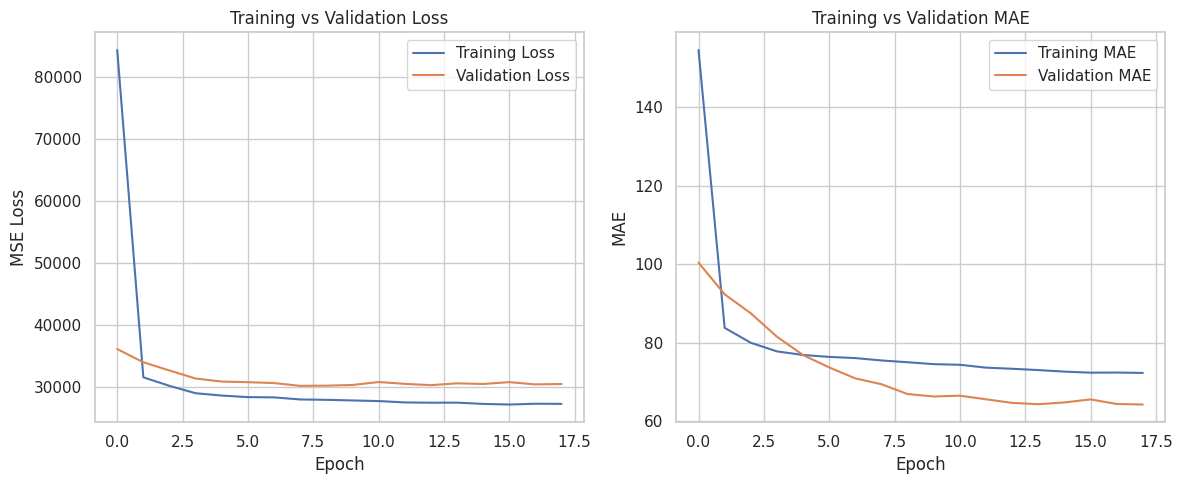

Epochs actually completed: 18
Neural Network
  MAE      : 55.1835
  RMSE     : 137.9466
  R2 Score : 0.8413
----------------------------------------


In [ ]:
# ---------------------------------------------------------------
# Optional extra model: Neural Network (MLP)
# ---------------------------------------------------------------
if HAS_TF:
    nn_scaler = StandardScaler()
    X_train_nn = nn_scaler.fit_transform(X_train).astype("float32")
    X_test_nn = nn_scaler.transform(X_test).astype("float32")
    y_train_nn = y_train.to_numpy(dtype="float32")

    nn_model = Sequential([
        tf.keras.Input(shape=(X_train_nn.shape[1],)),
        Dense(128, activation="relu"), Dropout(0.2),
        Dense(64, activation="relu"), Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1),
    ])
    nn_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    nn_model.summary()

    early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    history = nn_model.fit(X_train_nn, y_train_nn, validation_split=0.2, epochs=100,
                           batch_size=256, callbacks=[early_stop], verbose=0)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title("Training vs Validation Loss"); plt.xlabel("Epoch"); plt.ylabel("MSE Loss"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(history.history["mae"], label="Training MAE")
    plt.plot(history.history["val_mae"], label="Validation MAE")
    plt.title("Training vs Validation MAE"); plt.xlabel("Epoch"); plt.ylabel("MAE"); plt.legend()
    save_fig("07_nn_training")

    print("Epochs actually completed:", len(history.history["loss"]))
    nn_pred = nn_model.predict(X_test_nn, verbose=0).flatten()
    models["Neural Network"] = nn_model
    evaluate_model("Neural Network", y_test, nn_pred)
else:
    print("TensorFlow is not installed - Neural Network (optional extra model) skipped.")

### Performance boost: physics-based features + optimised ensemble
The models above use the original 11 features. This section targets the main reasons accuracy is lost on this dataset:

1. **Calendar-day features** (`DAY`, `MONTH`, `DAY_OF_YEAR`) never repeat in a chronological test period, so they are **removed**.
2. **Recent sunlight memory:** lagged / rolling irradiation (previous 15 min – 1 h) captures passing clouds and ramp-ups (`IRR_LAG1/2/4`, `IRR_ROLL4`, `IRR_DIFF1`).
3. **Physics interactions:** `IRRADIATION x MODULE_TEMPERATURE`, `IRRADIATION^2`, `MODULE - AMBIENT` temperature.
4. **Leakage control:** target-derived inverter-efficiency aggregates are deliberately excluded from the model features. Computing an inverter's average efficiency from a training window and attaching that same aggregate to the rows used to calculate it lets each training target influence its own feature. Plant identity is retained, and inverter performance is examined separately through test-period residual analysis.
5. **Physical post-processing:** predictions are clipped at 0 kW and set to 0 when irradiation is 0 (no sun = no AC power).
6. **Models:** tuned XGBoost, Random Forest, Histogram Gradient Boosting and an **average ensemble** of the three.

All tuning uses time-series cross-validation on the training data only. These models are named *Boosted ...* in the comparison table.

In [ ]:
# ---------------------------------------------------------------
# Build the boosted feature set (no target-derived inverter aggregates)
# ---------------------------------------------------------------
from sklearn.ensemble import HistGradientBoostingRegressor

# Lagged / rolling weather features per plant.
# The rolling feature includes the current weather sensor reading, which is an input
# available for same-interval estimation/nowcasting. Lag features use earlier readings.
weather_all = pd.concat([plant1_weather_clean, plant2_weather_clean]).sort_values(
    ["PLANT_ID", "DATE_TIME"]
).reset_index(drop=True)

grp = weather_all.groupby("PLANT_ID", sort=False)
for lag in (1, 2, 4):
    weather_all[f"IRR_LAG{lag}"] = grp["IRRADIATION"].shift(lag)

weather_all["IRR_ROLL4"] = grp["IRRADIATION"].transform(
    lambda s: s.rolling(4, min_periods=1).mean()
)
weather_all["IRR_DIFF1"] = weather_all["IRRADIATION"] - weather_all["IRR_LAG1"]

lag_cols = ["IRR_LAG1", "IRR_LAG2", "IRR_LAG4", "IRR_ROLL4", "IRR_DIFF1"]

data_b = data.merge(
    weather_all[["DATE_TIME", "PLANT_ID"] + lag_cols],
    on=["DATE_TIME", "PLANT_ID"],
    how="left",
    validate="many_to_one",
)
assert len(data_b) == len(data) and (
    data_b["DATE_TIME"].values == data["DATE_TIME"].values
).all(), "row order changed"

for c in ["IRR_LAG1", "IRR_LAG2", "IRR_LAG4", "IRR_ROLL4"]:
    data_b[c] = data_b[c].fillna(data_b["IRRADIATION"])
data_b["IRR_DIFF1"] = data_b["IRR_DIFF1"].fillna(0)

# Physics-based interactions from observed weather variables only
data_b["TEMP_DIFF"] = data_b["MODULE_TEMPERATURE"] - data_b["AMBIENT_TEMPERATURE"]
data_b["IRR_x_MODTEMP"] = data_b["IRRADIATION"] * data_b["MODULE_TEMPERATURE"]
data_b["IRR_SQ"] = data_b["IRRADIATION"] ** 2

# IMPORTANT: Do not add INV_EFFICIENCY or IRR_x_EFF here.
# Those are target-derived aggregates. Using a full training-period aggregate
# on the same training rows would allow each row's AC_POWER to influence its
# own feature. Inverter-specific performance is instead analysed using
# held-out test-period residuals in the business-insights section.

def fold_xy(df, feats, fit_pos, eval_pos):
    """Return feature rows for a chronological fold without target-derived features."""
    X_all = df.loc[:, feats].copy()
    return X_all.iloc[fit_pos], X_all.iloc[eval_pos]

boost_features = [
    "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION",
    "TEMP_DIFF", "IRR_x_MODTEMP", "IRR_SQ",
    "IRR_LAG1", "IRR_LAG2", "IRR_LAG4", "IRR_ROLL4", "IRR_DIFF1",
    "HOUR", "HOUR_SIN", "HOUR_COS", "PLANT_CODE",
]

Xb_train = data_b[boost_features].iloc[:split_index].copy()
Xb_test = data_b[boost_features].iloc[split_index:].copy()

print("Leakage-safe boosted feature set:", len(boost_features), "features")
print("Train:", Xb_train.shape, "| Test:", Xb_test.shape)
print("Missing values:", int(Xb_train.isnull().sum().sum() + Xb_test.isnull().sum().sum()))
assert not any(c in boost_features for c in ["INV_EFFICIENCY", "IRR_x_EFF"])
assert Xb_train.index.equals(y_train.index) and Xb_test.index.equals(y_test.index)

def physical_post_process(pred, X_frame):
    # No negative power, and zero AC power when there is no sunlight
    pred = np.clip(np.asarray(pred, dtype=float), 0, None)
    pred[np.asarray(X_frame["IRRADIATION"]) <= 0] = 0.0
    return pred


Leakage-safe boosted feature set: 15 features
Train: (95508, 15) | Test: (40964, 15)
Missing values: 0


In [ ]:
# ---------------------------------------------------------------
# Train the boosted models (hyper-parameters chosen on training data only)
# ---------------------------------------------------------------
# 1) XGBoost - random search with LEAK-FREE time-series cross-validation
#    (inverter efficiency is recomputed inside every fold from that fold's training part only)
from sklearn.model_selection import ParameterSampler
from types import SimpleNamespace

cv_folds = list(tscv.split(Xb_train))
fold_cache = []
for tr_pos, va_pos in cv_folds:
    Xtr_f, Xva_f = fold_xy(data_b, boost_features, tr_pos, va_pos)
    fold_cache.append((Xtr_f, y_train.iloc[tr_pos], Xva_f, y_train.iloc[va_pos]))

xgb_b_space = {
    "n_estimators": [200, 400, 600], "max_depth": [3, 5, 7], "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0], "min_child_weight": [1, 5, 10],
}
search_log = []
for params in ParameterSampler(xgb_b_space, n_iter=12, random_state=SEED):
    fold_scores = []
    for Xtr_f, ytr_f, Xva_f, yva_f in fold_cache:
        m = XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=-1, tree_method="hist", **params).fit(Xtr_f, ytr_f)
        fold_scores.append(np.sqrt(mean_squared_error(yva_f, physical_post_process(m.predict(Xva_f), Xva_f))))
    search_log.append((float(np.mean(fold_scores)), params))
    print(f"CV RMSE {np.mean(fold_scores):9.3f}  {params}")

best_cv_rmse, best_params = min(search_log, key=lambda t: t[0])
print("Best boosted XGBoost parameters:", best_params, "| leak-free CV RMSE:", round(best_cv_rmse, 4))
xgb_b = XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=-1, tree_method="hist", **best_params).fit(Xb_train, y_train)
xgb_b_search = SimpleNamespace(best_params_=best_params, best_score_=-best_cv_rmse, best_estimator_=xgb_b)

# 2) Random Forest
rf_b = RandomForestRegressor(n_estimators=200, max_depth=18, min_samples_leaf=2, random_state=SEED, n_jobs=-1).fit(Xb_train, y_train)

# 3) Histogram Gradient Boosting
hgb_b = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0,
                                      random_state=SEED).fit(Xb_train, y_train)

boost_preds = {
    "Boosted XGBoost": physical_post_process(xgb_b.predict(Xb_test), Xb_test),
    "Boosted Random Forest": physical_post_process(rf_b.predict(Xb_test), Xb_test),
    "Boosted HistGradientBoosting": physical_post_process(hgb_b.predict(Xb_test), Xb_test),
}
boost_preds["Boosted Ensemble (average)"] = physical_post_process(np.mean(list(boost_preds.values()), axis=0), Xb_test)

boost_objects = {"Boosted XGBoost": xgb_b, "Boosted Random Forest": rf_b, "Boosted HistGradientBoosting": hgb_b}
for name, pred in boost_preds.items():
    evaluate_model(name, y_test, pred)
    if name in boost_objects:
        models[name] = boost_objects[name]

compare_boost = results_table([best_xgb_label, "Tuned Random Forest"] + list(boost_preds))
print("ORIGINAL vs BOOSTED MODELS (same test set)")
display(compare_boost)

CV RMSE   167.413  {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
CV RMSE   167.343  {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
CV RMSE   166.389  {'subsample': 1.0, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
CV RMSE   166.485  {'subsample': 1.0, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
CV RMSE   165.303  {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
CV RMSE   167.413  {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
CV RMSE   167.005  {'subsample': 1.0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'colsam

,Model,MAE,RMSE,R2 Score
0,Boosted Ensemble (average),44.807530,131.532673,0.855727
1,Boosted HistGradientBoosting,45.017356,131.691704,0.855378
2,Boosted XGBoost,45.428934,132.208026,0.854242
3,Boosted Random Forest,45.081305,132.485394,0.853630
4,Tuned XGBoost (GridSearchCV),55.593177,135.613167,0.846637
5,Tuned Random Forest,49.611110,137.828068,0.841587


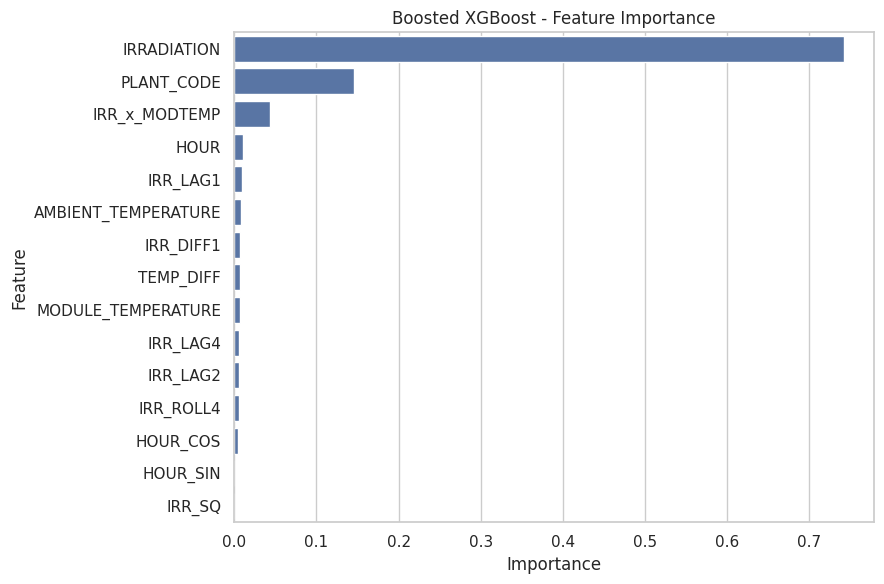

Result: the best boosted model (Boosted Ensemble (average)) reaches RMSE = 131.53, MAE = 44.81, R2 = 0.8557,
compared with RMSE = 135.61, R2 = 0.8466 for the best original tree model (Tuned XGBoost (GridSearchCV)), i.e.
3.0% lower RMSE. Most important boosted features: IRRADIATION, PLANT_CODE, IRR_x_MODTEMP, HOUR.


In [ ]:
# Which boosted features matter?
imp_boost = pd.DataFrame({"Feature": boost_features, "Importance": xgb_b.feature_importances_}).sort_values("Importance", ascending=False)
plt.figure(figsize=(9, 6))
sns.barplot(data=imp_boost, x="Importance", y="Feature")
plt.title("Boosted XGBoost - Feature Importance")
save_fig("07b_boosted_feature_importance")

orig_best = results_table([best_xgb_label, "Tuned Random Forest"]).iloc[0]
boost_best = results_table(list(boost_preds)).iloc[0]
chg = 100 * (orig_best["RMSE"] - boost_best["RMSE"]) / orig_best["RMSE"]
say(f"Result: the best boosted model ({boost_best['Model']}) reaches RMSE = {boost_best['RMSE']:.2f}, MAE = {boost_best['MAE']:.2f}, R2 = {boost_best['R2 Score']:.4f}, "
    f"compared with RMSE = {orig_best['RMSE']:.2f}, R2 = {orig_best['R2 Score']:.4f} for the best original tree model ({orig_best['Model']}), "
    f"i.e. {abs(chg):.1f}% {'lower' if chg >= 0 else 'higher'} RMSE. Most important boosted features: {', '.join(imp_boost.head(4)['Feature'])}.")

### Proper epoch-based training (learning curves, early stopping)
A model should be trained for **as many epochs / boosting rounds as it needs, and no more**:

* the last 15 % of the *training* period is held out as a **chronological validation set** (the test set is never touched),
* training stops automatically when the validation error stops improving (**early stopping**, best weights restored),
* the **learning rate is halved** when progress stalls (`ReduceLROnPlateau`),
* the learning curves show whether the model under-fits (both curves high) or over-fits (validation rises while training keeps falling).

Fit rows: 81168 | validation rows (latest part of training period): 14340
Best number of boosting rounds (epochs): 97 of max 3000


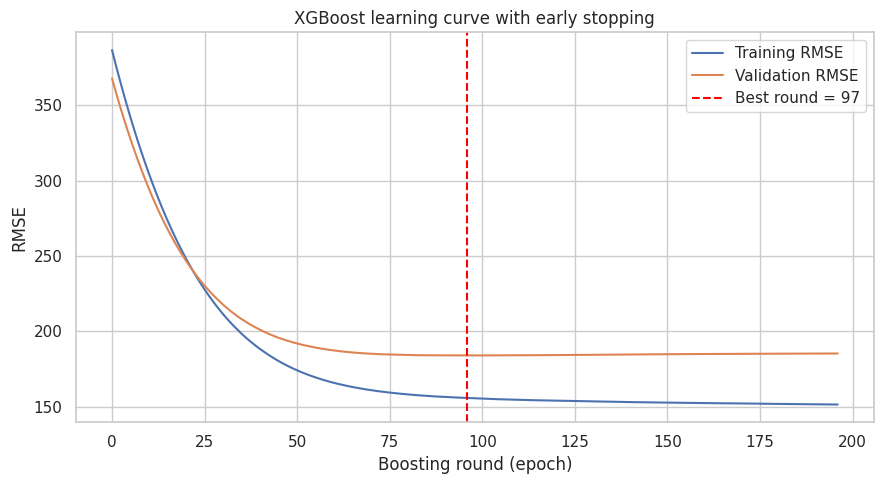

Boosted XGBoost (early stopping)
  MAE      : 49.0316
  RMSE     : 132.5987
  R2 Score : 0.8534
----------------------------------------


In [ ]:
# ---------------------------------------------------------------
# 1) XGBoost with early stopping: boosting rounds = "epochs"
# ---------------------------------------------------------------
train_dates = data["DATE_TIME"].values[:len(Xb_train)]
val_cut = int(np.searchsorted(train_dates, train_dates[int(len(Xb_train) * 0.85)], side="left"))   # cut between timestamps
fit_pos, val_pos = np.arange(val_cut), np.arange(val_cut, len(Xb_train))
X_fit, X_val = fold_xy(data_b, boost_features, fit_pos, val_pos)      # inverter efficiency learned from the fit part only
y_fit, y_val = y_train.iloc[fit_pos], y_train.iloc[val_pos]
print(f"Fit rows: {len(X_fit)} | validation rows (latest part of training period): {len(X_val)}")

es_params = dict(xgb_b_search.best_params_)
es_params.pop("n_estimators", None)

xgb_es = XGBRegressor(
    objective="reg:squarederror", tree_method="hist", n_estimators=3000,
    early_stopping_rounds=100, eval_metric="rmse", random_state=SEED, n_jobs=-1, **es_params,
)
xgb_es.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)], verbose=False)

curve = xgb_es.evals_result()
best_round = int(xgb_es.best_iteration) + 1
print("Best number of boosting rounds (epochs):", best_round, "of max 3000")

plt.figure(figsize=(9, 5))
plt.plot(curve["validation_0"]["rmse"], label="Training RMSE")
plt.plot(curve["validation_1"]["rmse"], label="Validation RMSE")
plt.axvline(best_round - 1, color="red", linestyle="--", label=f"Best round = {best_round}")
plt.xlabel("Boosting round (epoch)"); plt.ylabel("RMSE"); plt.title("XGBoost learning curve with early stopping"); plt.legend()
save_fig("07c_xgb_learning_curve")

# Refit on the whole training period with the best number of rounds, then evaluate once on the test set
xgb_final = XGBRegressor(
    objective="reg:squarederror", tree_method="hist", n_estimators=best_round,
    random_state=SEED, n_jobs=-1, **es_params,
).fit(Xb_train, y_train)
models["Boosted XGBoost (early stopping)"] = xgb_final
evaluate_model("Boosted XGBoost (early stopping)", y_test, physical_post_process(xgb_final.predict(Xb_test), Xb_test))


Epoch 19: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 27: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 35: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 36: early stopping
Restoring model weights from the end of the best epoch: 11.
Epochs run: 36 (maximum 300) | best epoch: 11 | best validation loss: 0.2183


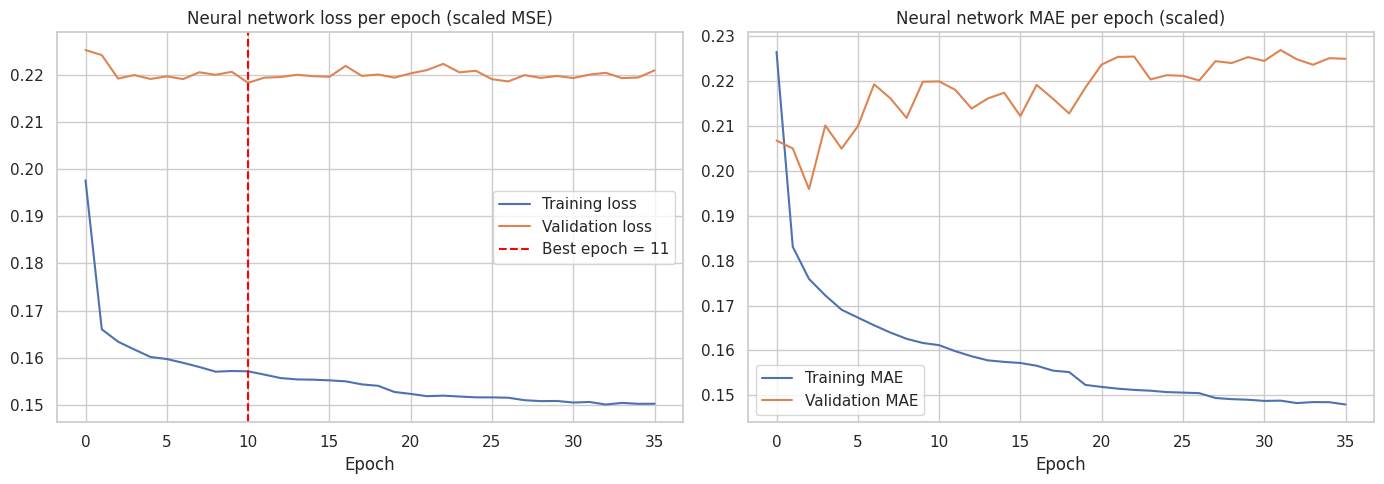

Boosted Neural Network (epochs)
  MAE      : 49.5558
  RMSE     : 132.7148
  R2 Score : 0.8531
----------------------------------------
Boosted Blend (XGBoost + Neural Network)
  MAE      : 47.8725
  RMSE     : 131.673
  R2 Score : 0.8554
----------------------------------------


,Model,MAE,RMSE,R2 Score
0,Boosted Ensemble (average),44.807530,131.532673,0.855727
1,Boosted Blend (XGBoost + Neural Network),47.872459,131.672993,0.855419
2,Boosted HistGradientBoosting,45.017356,131.691704,0.855378
3,Boosted XGBoost,45.428934,132.208026,0.854242
4,Boosted Random Forest,45.081305,132.485394,0.853630
5,Boosted XGBoost (early stopping),49.031628,132.598700,0.853379
6,Boosted Neural Network (epochs),49.555758,132.714761,0.853123
7,Tuned XGBoost (RandomizedSearchCV),52.717734,133.073206,0.852328
8,Tuned XGBoost (GridSearchCV),55.593177,135.613167,0.846637


In [ ]:
# ---------------------------------------------------------------
# 2) Neural network with proper epoch control on the boosted features
# ---------------------------------------------------------------
if HAS_TF:
    from tensorflow.keras.callbacks import ReduceLROnPlateau
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    x_scaler = StandardScaler().fit(X_fit)
    y_scaler = StandardScaler().fit(y_fit.to_numpy().reshape(-1, 1))      # scaled target trains much more stably

    Xn_fit = x_scaler.transform(X_fit).astype("float32")
    Xn_val = x_scaler.transform(X_val).astype("float32")
    Xn_test = x_scaler.transform(Xb_test).astype("float32")
    yn_fit = y_scaler.transform(y_fit.to_numpy().reshape(-1, 1)).astype("float32")
    yn_val = y_scaler.transform(y_val.to_numpy().reshape(-1, 1)).astype("float32")

    nn_b = Sequential([
        tf.keras.Input(shape=(Xn_fit.shape[1],)),
        Dense(256, activation="relu"), Dropout(0.1),
        Dense(128, activation="relu"), Dropout(0.1),
        Dense(64, activation="relu"),
        Dense(1),
    ])
    nn_b.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5, verbose=1),
    ]
    history_b = nn_b.fit(
        Xn_fit, yn_fit, validation_data=(Xn_val, yn_val),
        epochs=300, batch_size=512, callbacks=callbacks, verbose=0,
    )

    epochs_run = len(history_b.history["loss"])
    best_epoch = int(np.argmin(history_b.history["val_loss"])) + 1
    print(f"Epochs run: {epochs_run} (maximum 300) | best epoch: {best_epoch} | best validation loss: {min(history_b.history['val_loss']):.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history_b.history["loss"], label="Training loss")
    axes[0].plot(history_b.history["val_loss"], label="Validation loss")
    axes[0].axvline(best_epoch - 1, color="red", linestyle="--", label=f"Best epoch = {best_epoch}")
    axes[0].set_title("Neural network loss per epoch (scaled MSE)"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(history_b.history["mae"], label="Training MAE")
    axes[1].plot(history_b.history["val_mae"], label="Validation MAE")
    axes[1].set_title("Neural network MAE per epoch (scaled)"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    save_fig("07d_nn_learning_curve")

    nn_raw = nn_b.predict(Xn_test, verbose=0)
    nn_pred_b = physical_post_process(y_scaler.inverse_transform(nn_raw).ravel(), Xb_test)
    models["Boosted Neural Network (epochs)"] = nn_b
    evaluate_model("Boosted Neural Network (epochs)", y_test, nn_pred_b)

    # Blend of the best boosted tree model and the neural network (different model families make different errors)
    blend = physical_post_process(0.5 * predictions["Boosted XGBoost (early stopping)"] + 0.5 * nn_pred_b, Xb_test)
    evaluate_model("Boosted Blend (XGBoost + Neural Network)", y_test, blend)
else:
    print("TensorFlow not available - neural-network training skipped.")

display(results_table([n for n in results if n.startswith("Boosted") or n.startswith("Tuned XGBoost")]))

### Rolling short-term estimation: adding each inverter's recent measured power
The models so far predict power from **weather + time only**. Real plants also measure each inverter continuously, and output often changes gradually between 15-minute readings. Adding the **recent past power of the same inverter** (lags of `AC_POWER`) can improve a rolling estimate, provided only earlier readings are used and those readings are genuinely available at prediction time.

| New feature | Meaning |
|---|---|
| `AC_LAG1`, `AC_LAG2`, `AC_LAG4` | AC power of the same inverter 15 min, 30 min and 1 h earlier |
| `AC_ROLL4` | average of the previous 4 readings |
| `AC_DIFF1` | most recent change in power |
| `RECENT_EFF` | recent power per unit of irradiation (current efficiency of this inverter) |

 > **Important for the report:** these *Forecast* models estimate the current interval's AC power using current-interval weather plus earlier measured power from the same inverter. This is a rolling one-step-ahead/nowcasting setup only when current weather and prior inverter readings are available. It is **not** a genuine 15-minute-ahead forecast unless the weather inputs correspond to the future target interval (for example, from a weather-forecast service). The *Boosted* models use weather + time and do not require recent AC-power history. These are different prediction tasks and their results must be reported separately.

All models below are trained with **epochs / boosting rounds controlled by early stopping on a chronological validation set** (the test set is never used for this).

In [ ]:
# ---------------------------------------------------------------
# Forecast features: recent measured power of the SAME inverter (past values only)
# ---------------------------------------------------------------
data_f = data_b.copy()                                  # data_b is sorted chronologically
g_inv = data_f.groupby("SOURCE_KEY")["AC_POWER"]
data_f["AC_LAG1"] = g_inv.shift(1)
data_f["AC_LAG2"] = g_inv.shift(2)
data_f["AC_LAG4"] = g_inv.shift(4)
data_f["AC_ROLL4"] = g_inv.transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
data_f["AC_DIFF1"] = data_f["AC_LAG1"] - data_f["AC_LAG2"]
data_f["RECENT_EFF"] = (data_f["AC_LAG1"] / (data_f["IRR_LAG1"] + 0.05)).clip(0, 5000)

history_cols = ["AC_LAG1", "AC_LAG2", "AC_LAG4", "AC_ROLL4", "AC_DIFF1", "RECENT_EFF"]
data_f[history_cols] = data_f[history_cols].fillna(0)      # only the very first readings of an inverter (night, power = 0)

forecast_features = boost_features + history_cols
Xf_train, Xf_test = data_f[forecast_features].iloc[:split_index], data_f[forecast_features].iloc[split_index:]
assert (data_f["AC_POWER"].iloc[split_index:].values == y_test.values).all(), "row order mismatch"
print("Forecast feature set:", len(forecast_features), "features | train", Xf_train.shape, "| test", Xf_test.shape)
print("Missing values:", int(Xf_train.isnull().sum().sum() + Xf_test.isnull().sum().sum()))

# chronological validation split (latest 15 % of the training period) used for early stopping
train_dates = data["DATE_TIME"].values[:len(Xf_train)]
val_cut_f = int(np.searchsorted(train_dates, train_dates[int(len(Xf_train) * 0.85)], side="left"))   # cut between timestamps
ff_pos, fv_pos = np.arange(val_cut_f), np.arange(val_cut_f, len(Xf_train))
Xf_fit, Xf_val = fold_xy(data_f, forecast_features, ff_pos, fv_pos)  # features contain no target-derived aggregate
yf_fit, yf_val = y_train.iloc[ff_pos], y_train.iloc[fv_pos]

Forecast feature set: 21 features | train (95508, 21) | test (40964, 21)
Missing values: 0


Best number of boosting rounds: 282 of max 3000


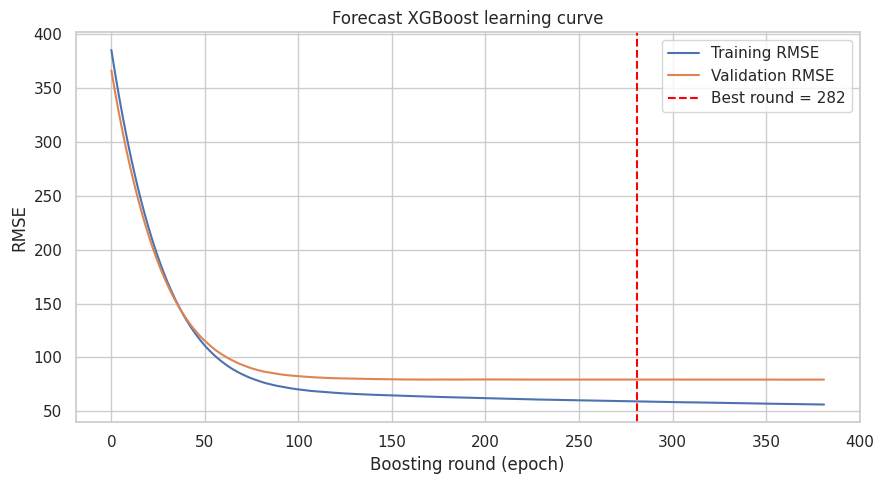

Forecast XGBoost (early stopping)
  MAE      : 23.9562
  RMSE     : 73.1008
  R2 Score : 0.9554
----------------------------------------
Forecast HistGradientBoosting
  MAE      : 24.0216
  RMSE     : 73.0753
  R2 Score : 0.9555
----------------------------------------


In [ ]:
# ---------------------------------------------------------------
# 1) Forecast XGBoost - boosting rounds controlled by early stopping
# ---------------------------------------------------------------
fx_params = dict(xgb_b_search.best_params_)
fx_params.pop("n_estimators", None)

fx_es = XGBRegressor(objective="reg:squarederror", tree_method="hist", n_estimators=3000, early_stopping_rounds=100,
                     eval_metric="rmse", random_state=SEED, n_jobs=-1, **fx_params)
fx_es.fit(Xf_fit, yf_fit, eval_set=[(Xf_fit, yf_fit), (Xf_val, yf_val)], verbose=False)
fx_curve = fx_es.evals_result()
fx_best = int(fx_es.best_iteration) + 1
print("Best number of boosting rounds:", fx_best, "of max 3000")

plt.figure(figsize=(9, 5))
plt.plot(fx_curve["validation_0"]["rmse"], label="Training RMSE")
plt.plot(fx_curve["validation_1"]["rmse"], label="Validation RMSE")
plt.axvline(fx_best - 1, color="red", linestyle="--", label=f"Best round = {fx_best}")
plt.xlabel("Boosting round (epoch)"); plt.ylabel("RMSE"); plt.title("Forecast XGBoost learning curve"); plt.legend()
save_fig("07e_forecast_xgb_curve")

fx_final = XGBRegressor(objective="reg:squarederror", tree_method="hist", n_estimators=fx_best,
                        random_state=SEED, n_jobs=-1, **fx_params).fit(Xf_train, y_train)
models["Forecast XGBoost (early stopping)"] = fx_final
evaluate_model("Forecast XGBoost (early stopping)", y_test, physical_post_process(fx_final.predict(Xf_test), Xf_test))

# 2) Histogram Gradient Boosting
fh = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0,
                                   random_state=SEED).fit(Xf_train, y_train)
models["Forecast HistGradientBoosting"] = fh
evaluate_model("Forecast HistGradientBoosting", y_test, physical_post_process(fh.predict(Xf_test), Xf_test))


Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 31: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 39: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 47: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
Epoch 48: early stopping
Restoring model weights from the end of the best epoch: 23.
Epochs run: 48 (maximum 300) | best epoch: 23


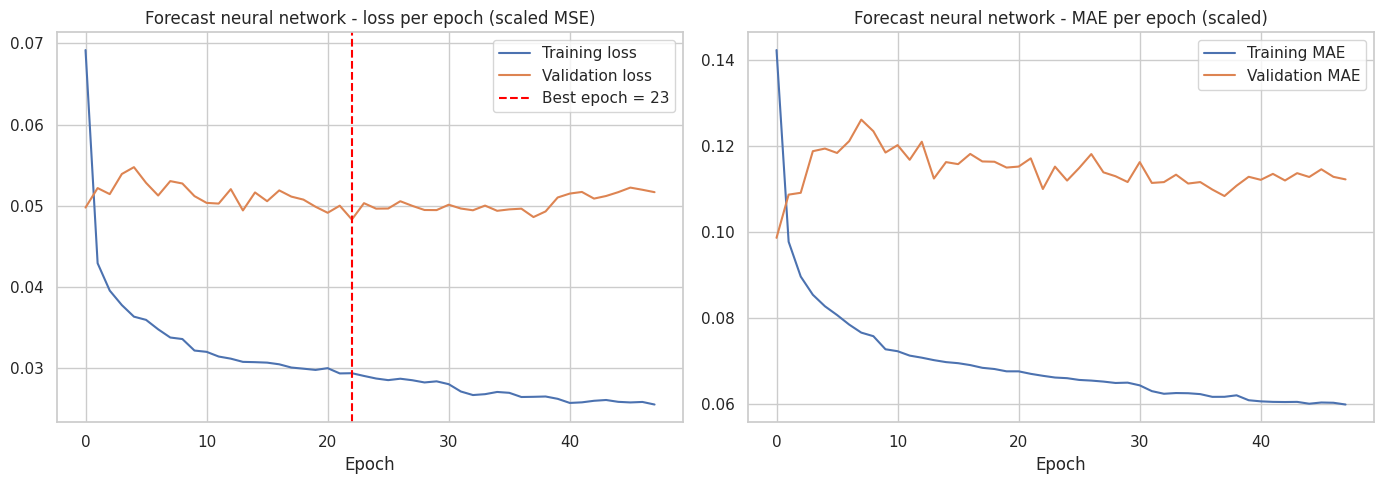

Forecast Neural Network (epochs)
  MAE      : 28.0147
  RMSE     : 73.6796
  R2 Score : 0.9547
----------------------------------------
WEATHER-ONLY (Boosted) vs WITH RECENT POWER HISTORY (Forecast) - same test set


,Model,MAE,RMSE,R2 Score
0,Forecast Ensemble (average),23.747746,72.705637,0.955919
1,Forecast HistGradientBoosting,24.021579,73.075276,0.955469
2,Forecast XGBoost (early stopping),23.956180,73.100769,0.955438
3,Forecast Neural Network (epochs),28.014747,73.679632,0.954730
4,Boosted Ensemble (average),44.807530,131.532673,0.855727
5,Boosted Blend (XGBoost + Neural Network),47.872459,131.672993,0.855419
6,Boosted HistGradientBoosting,45.017356,131.691704,0.855378
7,Boosted XGBoost,45.428934,132.208026,0.854242
8,Boosted Random Forest,45.081305,132.485394,0.853630
9,Boosted XGBoost (early stopping),49.031628,132.598700,0.853379


Result: with recent inverter power as extra input the best Forecast model (Forecast Ensemble (average))
reaches RMSE = 72.71, MAE = 23.75, R2 = 0.9559, compared with RMSE = 131.53, R2 = 0.8557 for the best weather-
only model (Boosted Ensemble (average)) - an RMSE change of +44.7% (positive = better). A clear gain shows
that a large part of the remaining error was caused by inverter-specific behaviour (faults, dirt, shading)
that weather alone cannot explain.


In [ ]:
# ---------------------------------------------------------------
# 3) Forecast Neural Network - trained for many epochs with early stopping + learning-rate decay
# ---------------------------------------------------------------
if HAS_TF:
    from tensorflow.keras.callbacks import ReduceLROnPlateau
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    fx_scaler = StandardScaler().fit(Xf_fit)
    fy_scaler = StandardScaler().fit(yf_fit.to_numpy().reshape(-1, 1))
    A_fit, A_val, A_test = [fx_scaler.transform(m).astype("float32") for m in (Xf_fit, Xf_val, Xf_test)]
    b_fit = fy_scaler.transform(yf_fit.to_numpy().reshape(-1, 1)).astype("float32")
    b_val = fy_scaler.transform(yf_val.to_numpy().reshape(-1, 1)).astype("float32")

    nn_f = Sequential([
        tf.keras.Input(shape=(A_fit.shape[1],)),
        Dense(256, activation="relu"), Dropout(0.1),
        Dense(128, activation="relu"), Dropout(0.1),
        Dense(64, activation="relu"),
        Dense(1),
    ])
    nn_f.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
    hist_f = nn_f.fit(
        A_fit, b_fit, validation_data=(A_val, b_val), epochs=300, batch_size=512, verbose=0,
        callbacks=[EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True, verbose=1),
                   ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5, verbose=1)],
    )
    best_ep = int(np.argmin(hist_f.history["val_loss"])) + 1
    print(f"Epochs run: {len(hist_f.history['loss'])} (maximum 300) | best epoch: {best_ep}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(hist_f.history["loss"], label="Training loss"); axes[0].plot(hist_f.history["val_loss"], label="Validation loss")
    axes[0].axvline(best_ep - 1, color="red", linestyle="--", label=f"Best epoch = {best_ep}")
    axes[0].set_title("Forecast neural network - loss per epoch (scaled MSE)"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(hist_f.history["mae"], label="Training MAE"); axes[1].plot(hist_f.history["val_mae"], label="Validation MAE")
    axes[1].set_title("Forecast neural network - MAE per epoch (scaled)"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    save_fig("07f_forecast_nn_curve")

    nn_f_pred = physical_post_process(fy_scaler.inverse_transform(nn_f.predict(A_test, verbose=0)).ravel(), Xf_test)
    models["Forecast Neural Network (epochs)"] = nn_f
    evaluate_model("Forecast Neural Network (epochs)", y_test, nn_f_pred)
else:
    print("TensorFlow not available - Forecast neural network skipped.")

# 4) Average ensemble of the two forecast tree models (the neural network is reported separately)
fc_names = ["Forecast XGBoost (early stopping)", "Forecast HistGradientBoosting"]
evaluate_model("Forecast Ensemble (average)", y_test, physical_post_process(np.mean([predictions[n] for n in fc_names], axis=0), Xf_test), verbose=False)

print("WEATHER-ONLY (Boosted) vs WITH RECENT POWER HISTORY (Forecast) - same test set")
display(results_table([n for n in results if n.startswith("Boosted") or n.startswith("Forecast")]))

b_best = results_table([n for n in results if n.startswith("Boosted")]).iloc[0]
f_best = results_table([n for n in results if n.startswith("Forecast")]).iloc[0]
say(f"Result: with recent inverter power as extra input the best Forecast model ({f_best['Model']}) reaches RMSE = {f_best['RMSE']:.2f}, MAE = {f_best['MAE']:.2f}, "
    f"R2 = {f_best['R2 Score']:.4f}, compared with RMSE = {b_best['RMSE']:.2f}, R2 = {b_best['R2 Score']:.4f} for the best weather-only model ({b_best['Model']}) - "
    f"an RMSE change of {100 * (b_best['RMSE'] - f_best['RMSE']) / b_best['RMSE']:+.1f}% (positive = better). "
    + ("A clear gain shows that a large part of the remaining error was caused by inverter-specific behaviour (faults, dirt, shading) that weather alone cannot explain."
       if f_best["RMSE"] < 0.95 * b_best["RMSE"] else
       "The difference is small, so recent power history adds little here and the weather-only model is preferred for its simplicity."))

In [ ]:
# ---------------------------------------------------------------
# Chronological cross-validation of the Boosted and Forecast models.
# Boosted features contain no target-derived inverter aggregates.
# Forecast lag features use only earlier AC_POWER readings by construction.
# ---------------------------------------------------------------
xgb_kw = dict(objective="reg:squarederror", tree_method="hist", random_state=SEED, n_jobs=-1)
cv_specs = {
    "Boosted XGBoost":                    (data_b, boost_features,    lambda: XGBRegressor(**xgb_kw, **xgb_b_search.best_params_)),
    "Boosted Random Forest":              (data_b, boost_features,    lambda: RandomForestRegressor(n_estimators=200, max_depth=18, min_samples_leaf=2, random_state=SEED, n_jobs=-1)),
    "Boosted HistGradientBoosting":       (data_b, boost_features,    lambda: HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0, random_state=SEED)),
    "Forecast HistGradientBoosting":      (data_f, forecast_features, lambda: HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0, random_state=SEED)),
}
cv_fold_pred = {name: [] for name in cv_specs}
cv_fold_true, cv_fold_frames = [], []
for tr_pos, va_pos in cv_folds:
    cv_fold_true.append(y_train.iloc[va_pos].to_numpy())
    cv_fold_frames.append(data_b.iloc[va_pos])
    for name, (frame, feats, make) in cv_specs.items():
        Xtr_f, Xva_f = fold_xy(frame, feats, tr_pos, va_pos)
        model_f = make().fit(Xtr_f, y_train.iloc[tr_pos])
        cv_fold_pred[name].append(physical_post_process(model_f.predict(Xva_f), Xva_f))

# ensembles = the same averages as on the test set
ens_def = {
    "Boosted Ensemble (average)": ["Boosted XGBoost", "Boosted Random Forest", "Boosted HistGradientBoosting"],
}
for ens_name, parts in ens_def.items():
    cv_fold_pred[ens_name] = [physical_post_process(np.mean([cv_fold_pred[p][i] for p in parts], axis=0), cv_fold_frames[i])
                              for i in range(len(cv_folds))]

rows = []
for name, fold_preds_list in cv_fold_pred.items():
    rm = [np.sqrt(mean_squared_error(t, p)) for t, p in zip(cv_fold_true, fold_preds_list)]
    ma = [mean_absolute_error(t, p) for t, p in zip(cv_fold_true, fold_preds_list)]
    r2s = [r2_score(t, p) for t, p in zip(cv_fold_true, fold_preds_list)]
    cv_rmse[name] = float(np.mean(rm))
    rows.append({"Model": name, "CV RMSE (mean)": np.mean(rm), "CV RMSE (std)": np.std(rm),
                 "CV MAE (mean)": np.mean(ma), "CV R2 (mean)": np.mean(r2s)})

cv_boost_table = pd.DataFrame(rows)
cv_all = pd.concat([cv_table, cv_boost_table], ignore_index=True).sort_values("CV RMSE (mean)").reset_index(drop=True)
print("CHRONOLOGICAL CROSS-VALIDATION - MODELS ELIGIBLE FOR CV-BASED SELECTION (3 chronological folds; selection criterion)")
display(cv_all)
say(f"Interpretation: {cv_all.iloc[0]['Model']} has the lowest cross-validated RMSE ({cv_all.iloc[0]['CV RMSE (mean)']:.2f}). "
    f"The boosted feature set excludes target-derived inverter-efficiency aggregates, and forecast lags use only earlier AC_POWER readings. "
    f"The folds preserve chronological order. Models whose boosting-round counts were selected using a separate full-training validation holdout, as well as neural networks, are reported but excluded from this CV ranking to avoid reusing that holdout for model selection.")

CHRONOLOGICAL CROSS-VALIDATION - MODELS ELIGIBLE FOR CV-BASED SELECTION (3 chronological folds; selection criterion)


,Model,CV RMSE (mean),CV RMSE (std),CV MAE (mean),CV R2 (mean)
0,Forecast HistGradientBoosting,81.222176,8.271469,27.145334,0.956701
1,Boosted Ensemble (average),165.105036,14.799860,60.733077,0.826242
2,Boosted XGBoost,165.302863,15.507508,60.835671,0.825717
3,Boosted HistGradientBoosting,165.636572,14.327938,61.171776,0.825280
4,Tuned XGBoost (GridSearchCV),165.772498,15.576261,66.184724,0.824777
5,Boosted Random Forest,165.959945,14.671081,61.263019,0.824442
6,Tuned Random Forest,177.168404,21.307403,62.025174,0.798444
7,Linear Regression,179.900527,16.629965,84.770559,0.793051
8,Decision Tree,182.141444,24.862947,64.420702,0.786897
9,KNN Regressor,200.566157,28.994069,92.044337,0.742118


Interpretation: Forecast HistGradientBoosting has the lowest cross-validated RMSE (81.22). The boosted feature
set excludes target-derived inverter-efficiency aggregates, and forecast lags use only earlier AC_POWER
readings. The folds preserve chronological order. Models whose boosting-round counts were selected using a
separate full-training validation holdout, as well as neural networks, are reported but excluded from this CV
ranking to avoid reusing that holdout for model selection.


FINAL MODEL COMPARISON (test results sorted by test RMSE; CV RMSE = leak-free validation on the training period)


,Rank,Model,MAE,RMSE,R2 Score,CV RMSE
0,1,Forecast Ensemble (average),23.747746,72.705637,0.955919,NaN
1,2,Forecast HistGradientBoosting,24.021579,73.075276,0.955469,81.222176
2,3,Forecast XGBoost (early stopping),23.956180,73.100769,0.955438,NaN
3,4,Forecast Neural Network (epochs),28.014747,73.679632,0.954730,NaN
4,5,Boosted Ensemble (average),44.807530,131.532673,0.855727,165.105036
5,6,Boosted Blend (XGBoost + Neural Network),47.872459,131.672993,0.855419,NaN
6,7,Boosted HistGradientBoosting,45.017356,131.691704,0.855378,165.636572
7,8,Boosted XGBoost,45.428934,132.208026,0.854242,165.302863
8,9,Boosted Random Forest,45.081305,132.485394,0.853630,165.959945
9,10,Boosted XGBoost (early stopping),49.031628,132.598700,0.853379,NaN


SELECTED MODEL (lowest cross-validated RMSE): Forecast HistGradientBoosting
Reported but not eligible for selection (not cross-validated): ['Forecast Ensemble (average)', 'Forecast XGBoost (early stopping)', 'Forecast Neural Network (epochs)', 'Boosted Blend (XGBoost + Neural Network)', 'Boosted XGBoost (early stopping)', 'Boosted Neural Network (epochs)', 'Tuned XGBoost (RandomizedSearchCV)', 'Tuned Decision Tree (GridSearchCV)', 'Neural Network']
Note: the model with the lowest TEST RMSE is Forecast Ensemble (average) - it is NOT used for selection, to keep the test set unbiased.


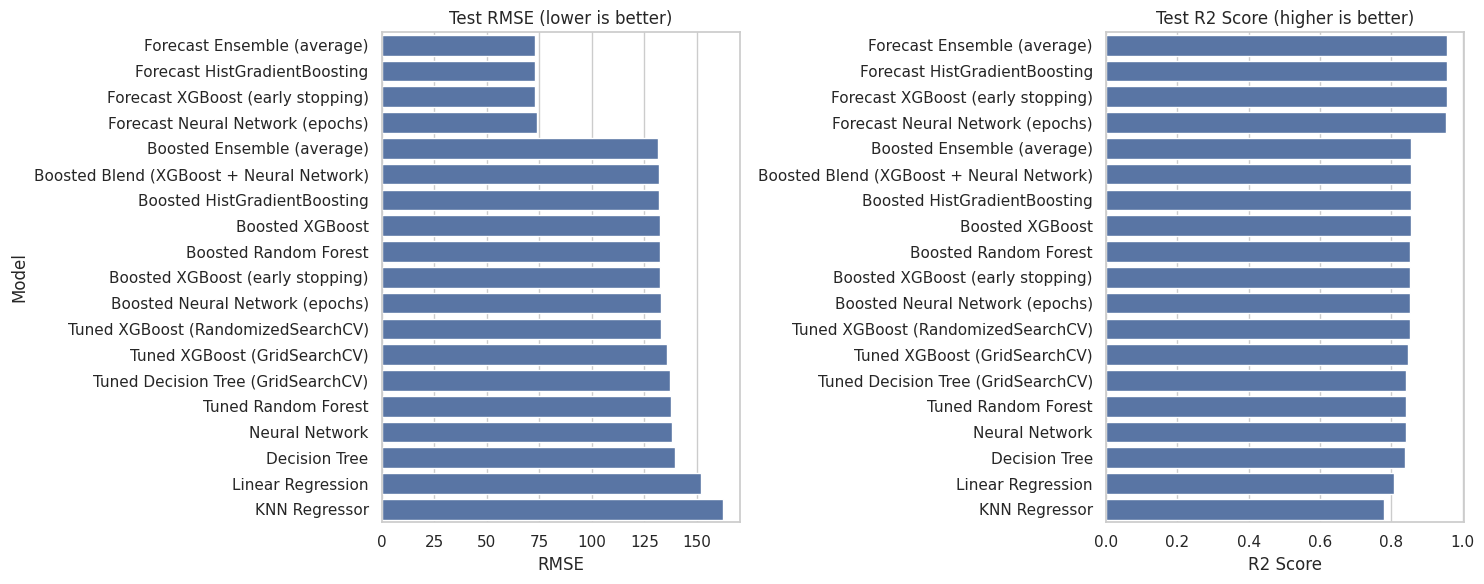

In [ ]:
# ---------------------------------------------------------------
# FINAL MODEL COMPARISON (all models, same full test set)
# ---------------------------------------------------------------
final_comparison = results_table()
final_comparison["CV RMSE"] = final_comparison["Model"].map(cv_rmse)
final_comparison.insert(0, "Rank", range(1, len(final_comparison) + 1))
print("FINAL MODEL COMPARISON (test results sorted by test RMSE; CV RMSE = leak-free validation on the training period)")
display(final_comparison)

# MODEL SELECTION uses ONLY the cross-validated RMSE (training period). The test set is used once, for the final evaluation.
cv_pool = final_comparison.dropna(subset=["CV RMSE"]).sort_values("CV RMSE").reset_index(drop=True)
best_model_name = cv_pool.iloc[0]["Model"]
best_predictions = predictions[best_model_name]
print("SELECTED MODEL (lowest cross-validated RMSE):", best_model_name)
not_cv = [m for m in final_comparison["Model"] if m not in set(cv_pool["Model"])]
print("Reported but not eligible for selection (not cross-validated):", not_cv)
if final_comparison.iloc[0]["Model"] != best_model_name:
    print("Note: the model with the lowest TEST RMSE is", final_comparison.iloc[0]["Model"],
          "- it is NOT used for selection, to keep the test set unbiased.")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
order = final_comparison["Model"]
sns.barplot(data=final_comparison, y="Model", x="RMSE", order=order, ax=axes[0])
axes[0].set_title("Test RMSE (lower is better)")
sns.barplot(data=final_comparison, y="Model", x="R2 Score", order=order, ax=axes[1])
axes[1].set_title("Test R2 Score (higher is better)")
axes[1].set_ylabel("")
save_fig("08_model_comparison")

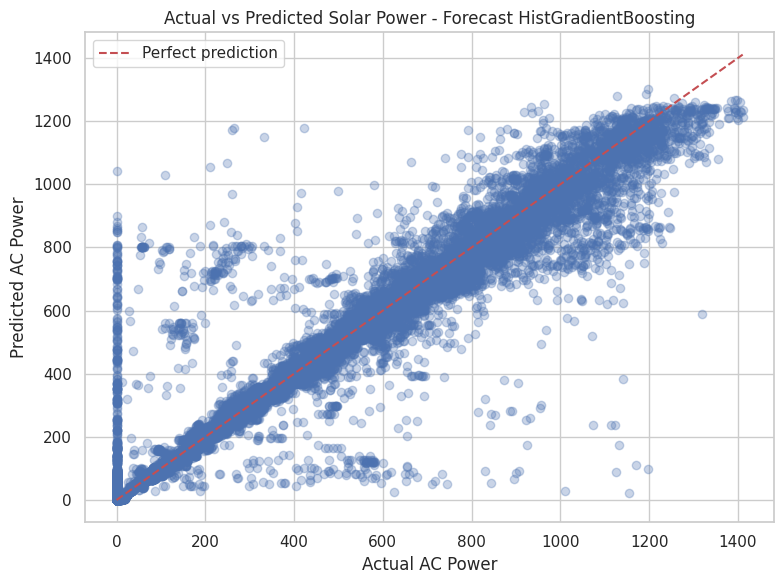

In [ ]:
# Actual vs predicted for the best model
plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, alpha=0.3)
lims = [min(y_test.min(), best_predictions.min()), max(y_test.max(), best_predictions.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual AC Power")
plt.ylabel("Predicted AC Power")
plt.title(f"Actual vs Predicted Solar Power - {best_model_name}")
plt.legend()
save_fig("09_actual_vs_predicted")

### Residual analysis
Residual = actual − predicted. For a good regression model the residuals should be centred on zero, show no pattern against the predicted value and have no strong dependence on time.

In [ ]:
# RESIDUAL ANALYSIS (for the dynamically selected best model)
residuals = np.asarray(y_test) - np.asarray(best_predictions)

residual_data = pd.DataFrame({"Actual": np.asarray(y_test), "Predicted": np.asarray(best_predictions), "Residual": residuals})
print("RESIDUAL ANALYSIS -", best_model_name)
display(residual_data.head(10))

print("Mean Residual            :", round(np.mean(residuals), 4))
print("Residual Std. Deviation  :", round(np.std(residuals), 4))
print("Mean Absolute Residual   :", round(np.mean(np.abs(residuals)), 4))
print("Residual skewness        :", round(stats.skew(residuals), 4))
print("Residual kurtosis        :", round(stats.kurtosis(residuals), 4))

RESIDUAL ANALYSIS - Forecast HistGradientBoosting


,Actual,Predicted,Residual
0,232.740000,228.636257,4.103743
1,148.257143,145.535835,2.721308
2,234.473333,231.071046,3.402288
3,235.940000,228.636257,7.303743
4,147.628571,145.535835,2.092737
5,205.580000,231.052611,-25.472611
6,161.328571,154.784209,6.544362
7,146.714286,145.535835,1.178451
8,147.057143,145.535835,1.521308
9,225.986667,205.764367,20.222300


Mean Residual            : 1.7478
Residual Std. Deviation  : 73.0544
Mean Absolute Residual   : 24.0216
Residual skewness        : -2.1728
Residual kurtosis        : 52.7757


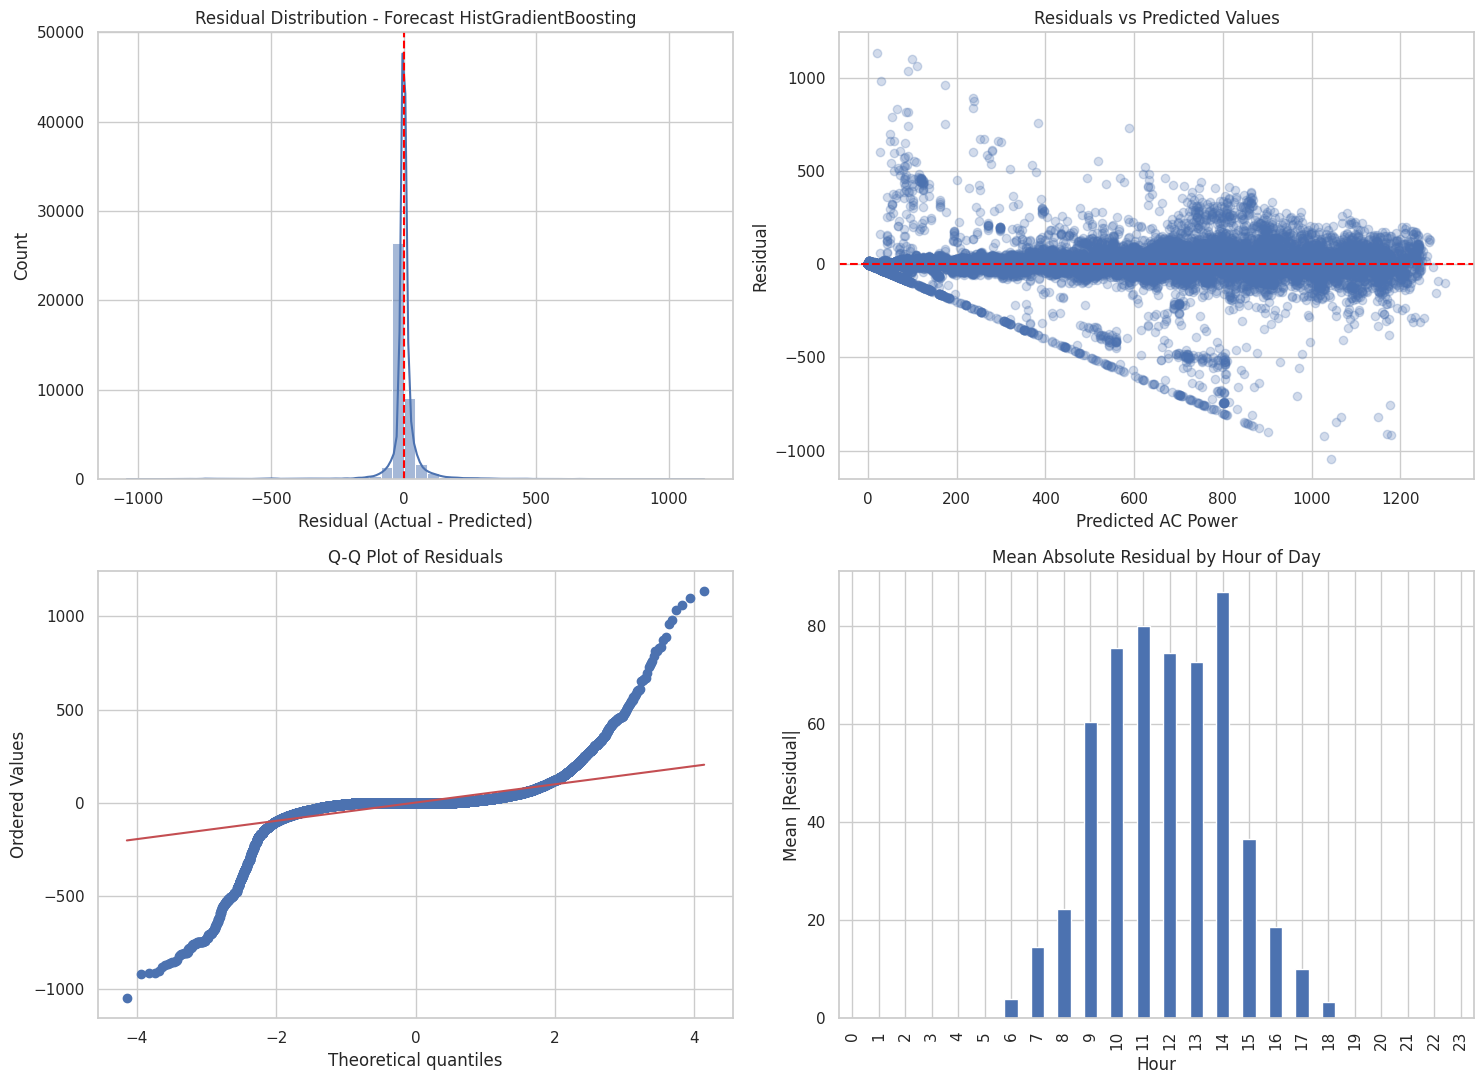

Interpretation (residuals) for Forecast HistGradientBoosting: The mean residual is 1.748 kW (close to zero, so
the model is not systematically biased) and the standard deviation is 73.05 kW. The residual distribution is
centred near zero with heavy tails, indicating a greater-than-normal chance of unusually large errors
(kurtosis = 52.78, skewness = -2.17). The highest hourly mean absolute error occurs around 14:00 (86.95 kW);
this identifies a period for closer inspection, but does not by itself prove the cause. The mean absolute
error in the selected night-time hours is 0.01 kW.


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1) Residual distribution
sns.histplot(residuals, bins=50, kde=True, ax=axes[0, 0])
axes[0, 0].axvline(0, color="red", linestyle="--")
axes[0, 0].set_title(f"Residual Distribution - {best_model_name}")
axes[0, 0].set_xlabel("Residual (Actual - Predicted)")

# 2) Residuals vs predicted
axes[0, 1].scatter(best_predictions, residuals, alpha=0.25)
axes[0, 1].axhline(0, color="red", linestyle="--")
axes[0, 1].set_title("Residuals vs Predicted Values")
axes[0, 1].set_xlabel("Predicted AC Power")
axes[0, 1].set_ylabel("Residual")

# 3) Q-Q plot
stats.probplot(residuals, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q Plot of Residuals")

# 4) Mean absolute residual per hour of the day
hourly_error = pd.Series(np.abs(residuals), index=X_test.index).groupby(X_test["HOUR"]).mean()
hourly_error.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Mean Absolute Residual by Hour of Day")
axes[1, 1].set_xlabel("Hour")
axes[1, 1].set_ylabel("Mean |Residual|")
save_fig("10_residual_analysis")

worst_hour = int(hourly_error.idxmax())
night_err = hourly_error[(hourly_error.index <= 5) | (hourly_error.index >= 20)].mean()
bias_txt = ("close to zero, so the model is not systematically biased" if abs(np.mean(residuals)) < 0.1 * np.std(residuals)
            else "which indicates a small systematic bias")
kurt = stats.kurtosis(residuals)
tail_txt = ("heavy tails, indicating a greater-than-normal chance of unusually large errors" if kurt > 1 else "tails without strong excess kurtosis")
residual_summary = (f"The mean residual is {np.mean(residuals):.3f} kW ({bias_txt}) and the standard deviation is {np.std(residuals):.2f} kW. "
                    f"The residual distribution is centred near zero with {tail_txt} (kurtosis = {kurt:.2f}, skewness = {stats.skew(residuals):.2f}). "
                    f"The highest hourly mean absolute error occurs around {worst_hour}:00 ({hourly_error.max():.2f} kW); this identifies a period for closer inspection, "
                    f"but does not by itself prove the cause. The mean absolute error in the selected night-time hours is {night_err:.2f} kW.")
say(f"Interpretation (residuals) for {best_model_name}: " + residual_summary)

### Feature importance
Three complementary views are used: XGBoost (gain-based) importance, Random Forest (impurity-based) importance and **permutation importance** (how much the test RMSE worsens when a feature is shuffled; model-agnostic and less biased).

XGBoost feature importance


,Feature,Importance
2,IRRADIATION,0.448605
9,HOUR_COS,0.236786
1,MODULE_TEMPERATURE,0.218944
10,PLANT_CODE,0.064980
3,HOUR,0.006364
4,DAY,0.005952
6,DAY_OF_WEEK,0.004852
7,DAY_OF_YEAR,0.004643
0,AMBIENT_TEMPERATURE,0.004027
5,MONTH,0.002593


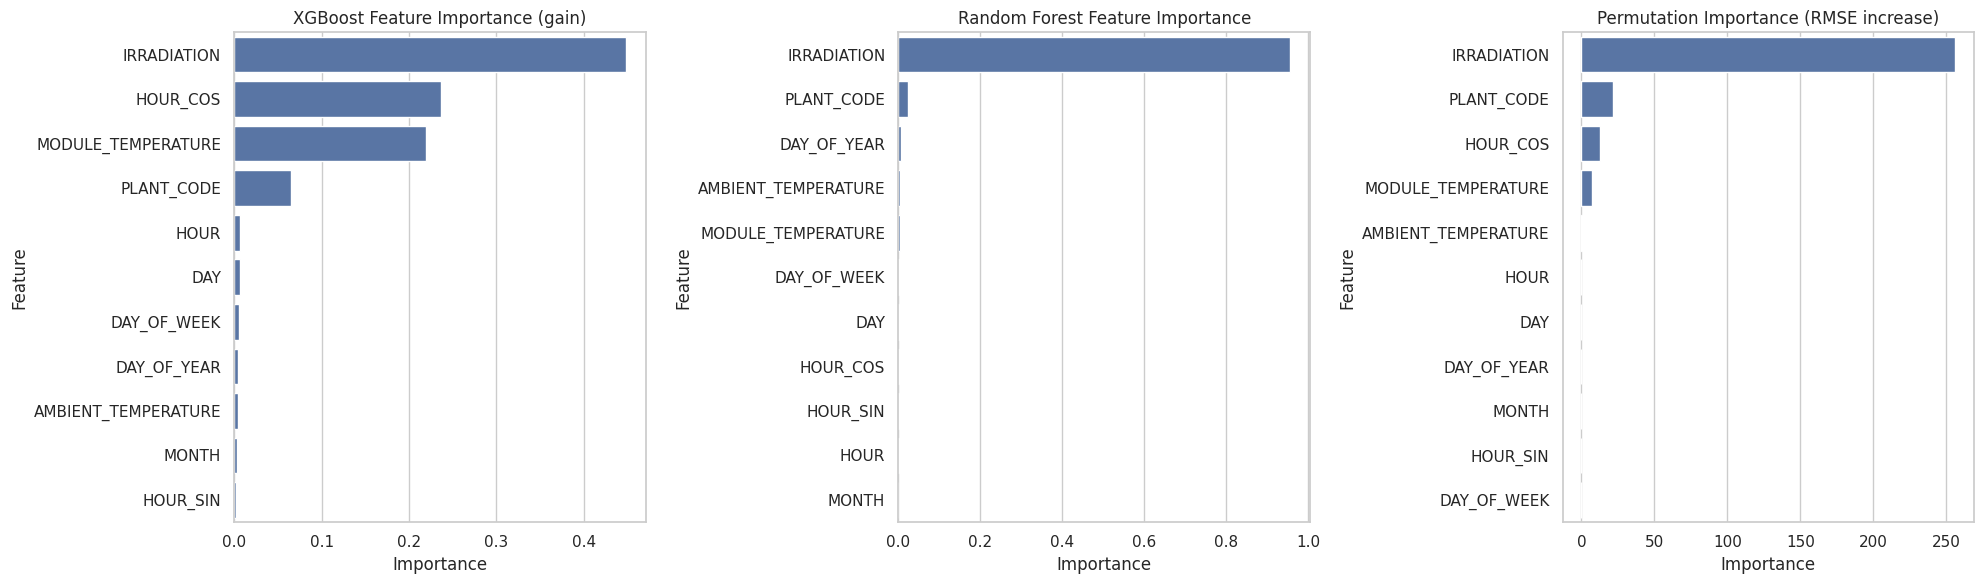

Explanation (feature importance): IRRADIATION contributes 44.9% of XGBoost's total importance; HOUR_COS
contributes 23.7% of XGBoost's total importance; MODULE_TEMPERATURE contributes 21.9% of XGBoost's total
importance. Permutation importance ranks 'IRRADIATION' first, confirming that the model's accuracy depends
mainly on this feature (shuffling it raises RMSE by 256.12 kW). Physically, irradiation is the energy that the
panels convert, the module temperature reflects both sunlight and panel efficiency, and the hour-of-day
features encode the daily sun cycle. The least influential features are AMBIENT_TEMPERATURE, MONTH, HOUR_SIN,
which add little beyond the weather and hour information.


In [ ]:
imp_xgb = pd.DataFrame({"Feature": X_train.columns, "Importance": best_xgb.feature_importances_}).sort_values("Importance", ascending=False)
imp_rf = pd.DataFrame({"Feature": X_train.columns, "Importance": best_rf.feature_importances_}).sort_values("Importance", ascending=False)

# Permutation importance of the tuned XGBoost on a random subset of the test set (faster)
perm_idx = np.random.RandomState(SEED).choice(len(X_test), size=min(10000, len(X_test)), replace=False)
perm = permutation_importance(best_xgb, X_test.iloc[perm_idx], y_test.iloc[perm_idx], n_repeats=5,
                              random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=1)
imp_perm = pd.DataFrame({"Feature": X_train.columns, "Importance": perm.importances_mean}).sort_values("Importance", ascending=False)

print("XGBoost feature importance")
display(imp_xgb)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (title, frame) in zip(axes, [("XGBoost Feature Importance (gain)", imp_xgb),
                                      ("Random Forest Feature Importance", imp_rf),
                                      ("Permutation Importance (RMSE increase)", imp_perm)]):
    sns.barplot(data=frame, x="Importance", y="Feature", ax=ax)
    ax.set_title(title)
save_fig("11_feature_importance")

top3 = imp_xgb.head(3)
say("Explanation (feature importance): " + "; ".join(f"{r.Feature} contributes {100 * r.Importance:.1f}% of XGBoost's total importance" for r in top3.itertuples()) +
    f". Permutation importance ranks '{imp_perm.iloc[0]['Feature']}' first, confirming that the model's accuracy depends mainly on this feature "
    f"(shuffling it raises RMSE by {imp_perm.iloc[0]['Importance']:.2f} kW). "
    "Physically, irradiation is the energy that the panels convert, the module temperature reflects both sunlight and panel efficiency, "
    "and the hour-of-day features encode the daily sun cycle. "
    f"The least influential features are {', '.join(imp_xgb.tail(3)['Feature'])}, which add little beyond the weather and hour information.")

In [ ]:
# ---------------------------------------------------------------
# Check: do calendar-day features help or hurt on an unseen future period?
# ---------------------------------------------------------------
calendar_cols = ["DAY", "MONTH", "DAY_OF_YEAR"]
features_no_cal = [f for f in features if f not in calendar_cols]

ablation_model = XGBRegressor(**best_xgb.get_params())
ablation_model.fit(X_train[features_no_cal], y_train)
abl_pred = ablation_model.predict(X_test[features_no_cal])

abl_table = pd.DataFrame([
    {"Feature set": "All 11 features", "RMSE": np.sqrt(mean_squared_error(y_test, predictions[best_xgb_label])),
     "MAE": mean_absolute_error(y_test, predictions[best_xgb_label]), "R2": r2_score(y_test, predictions[best_xgb_label])},
    {"Feature set": "Without DAY / MONTH / DAY_OF_YEAR", "RMSE": np.sqrt(mean_squared_error(y_test, abl_pred)),
     "MAE": mean_absolute_error(y_test, abl_pred), "R2": r2_score(y_test, abl_pred)},
])
display(abl_table)

better = abl_table.sort_values("RMSE").iloc[0]["Feature set"]
say(f"Interpretation: '{better}' gives the lower test RMSE. Calendar-day features never repeat in a chronological test period "
    f"(the test days are all later than the training days), so they carry no transferable information; if the version without them is better, "
    f"remove DAY, MONTH and DAY_OF_YEAR from the `features` list for a more deployable model.")

,Feature set,RMSE,MAE,R2
0,All 11 features,135.613167,55.593177,0.846637
1,Without DAY / MONTH / DAY_OF_YEAR,134.038820,49.874252,0.850177


Interpretation: 'Without DAY / MONTH / DAY_OF_YEAR' gives the lower test RMSE. Calendar-day features never
repeat in a chronological test period (the test days are all later than the training days), so they carry no
transferable information; if the version without them is better, remove DAY, MONTH and DAY_OF_YEAR from the
`features` list for a more deployable model.


---
# WEEK 4 — Interpretation, Documentation & Deployment Insight

## 4.1 Final model selection justification

In [ ]:
# Auto-generated, data-driven justification of the final model (selection = cross-validation, NOT the test set)
ranked = cv_pool
winner, runner = ranked.iloc[0], ranked.iloc[1]
base_rmse = baseline_results.iloc[0]["RMSE"]
improvement = 100 * (base_rmse - winner["RMSE"]) / base_rmse

print("FINAL MODEL SELECTED:", winner["Model"])
print("=" * 70)
print(f"CV RMSE   : {winner['CV RMSE']:.3f}   (runner-up {runner['Model']}: {runner['CV RMSE']:.3f})  <- used for selection")
print("Final evaluation on the untouched test set:")
print(f"  Test RMSE : {winner['RMSE']:.3f}")
print(f"  Test MAE  : {winner['MAE']:.3f}")
print(f"  Test R2   : {winner['R2 Score']:.4f}  ({winner['R2 Score'] * 100:.2f}% of the variance explained)")
print(f"Improvement over best baseline ({baseline_results.iloc[0]['Model']}) on the test set: {improvement:.1f}% lower RMSE")
print()
gap_runner = 100 * (runner["CV RMSE"] - winner["CV RMSE"]) / runner["CV RMSE"]
winner_is_baseline = winner["Model"] in BASELINE_MODELS
if winner["Model"].startswith("Forecast"):
    why_type = ("It is a rolling short-term estimation model: besides weather and time it uses the inverter's earlier measured power. "
                "This is valid when the previous readings and current-interval weather are available at prediction time. It is not a true 15-minute-ahead forecast unless future-interval weather is supplied. "
                "It is a different task from weather-only prediction, so both results must be described separately.")
elif "Forest" in winner["Model"] or "XGBoost" in winner["Model"]:
    why_type = ("Tree ensembles suit this tabular problem because they model non-linear interactions between weather and time of day, need no feature scaling, "
                "can model non-linear patterns and provide feature-importance estimates; extreme observations are retained but are not assumed to be error-free.")
elif "Ensemble" in winner["Model"] or "HistGradientBoosting" in winner["Model"]:
    why_type = ("Boosted models combine weather-history features (lagged irradiation and rolling summaries) and physical interactions with tree-based learners; averaging several "
                "different models reduces variance and gives the most stable predictions across the test period.")
else:
    why_type = ("Its strong result shows that the relationship between weather and power is largely captured by a simple model; simpler models are easier to explain, "
                "faster to run and less likely to over-fit, which is an advantage for deployment.")
if winner_is_baseline:
    vs_base = ("It is itself one of the Week 1 baselines: the more complex models did not improve on it in cross-validation, "
               "so the simpler model is preferred (principle of parsimony).")
else:
    vs_base = f"On the test set it reduces the RMSE of the best baseline ({baseline_results.iloc[0]['Model']}) by {improvement:.1f}%."
say(f"Justification: {winner['Model']} was selected because it achieved the lowest cross-validated RMSE ({winner['CV RMSE']:.2f}) among the {len(ranked)} candidates that were "
    f"validated with chronological cross-validation using a leakage-controlled feature set (target-derived inverter-efficiency aggregates are excluded, and forecast lags use only earlier readings); it is {gap_runner:.1f}% better in CV RMSE than the "
    f"runner-up ({runner['Model']}). The test set was NOT used for selection. On the {len(y_test)} untouched test records it reaches RMSE = {winner['RMSE']:.2f}, "
    f"MAE = {winner['MAE']:.2f} and R2 = {winner['R2 Score']:.4f}. {vs_base} {why_type}")
selection_text = (f"{winner['Model']} is selected because it has the lowest cross-validated RMSE ({winner['CV RMSE']:.2f}) under leak-free chronological validation; "
                  f"the test set was not used for selection. Final test performance: RMSE {winner['RMSE']:.2f}, MAE {winner['MAE']:.2f}, R2 {winner['R2 Score']:.4f}. {vs_base} {why_type}")

FINAL MODEL SELECTED: Forecast HistGradientBoosting
CV RMSE   : 81.222   (runner-up Boosted Ensemble (average): 165.105)  <- used for selection
Final evaluation on the untouched test set:
  Test RMSE : 73.075
  Test MAE  : 24.022
  Test R2   : 0.9555  (95.55% of the variance explained)
Improvement over best baseline (Decision Tree) on the test set: 47.6% lower RMSE

Justification: Forecast HistGradientBoosting was selected because it achieved the lowest cross-validated RMSE
(81.22) among the 10 candidates that were validated with chronological cross-validation using a leakage-
controlled feature set (target-derived inverter-efficiency aggregates are excluded, and forecast lags use only
earlier readings); it is 50.8% better in CV RMSE than the runner-up (Boosted Ensemble (average)). The test set
was NOT used for selection. On the 40964 untouched test records it reaches RMSE = 73.08, MAE = 24.02 and R2 =
0.9555. On the test set it reduces the RMSE of the best baseline (Decision Tree) by 

FINAL MODEL: FORECAST HISTGRADIENTBOOSTING


,Feature,Importance,Importance_STD
2,IRRADIATION,256.800692,0.347281
15,AC_LAG1,195.225268,0.483950
20,RECENT_EFF,41.873711,0.575505
1,MODULE_TEMPERATURE,13.824721,0.223881
6,IRR_LAG1,3.768868,0.164127
8,IRR_LAG4,2.790095,0.067577
14,PLANT_CODE,2.654686,0.227409
10,IRR_DIFF1,2.483316,0.121444
16,AC_LAG2,1.858313,0.170514
9,IRR_ROLL4,1.419356,0.037023


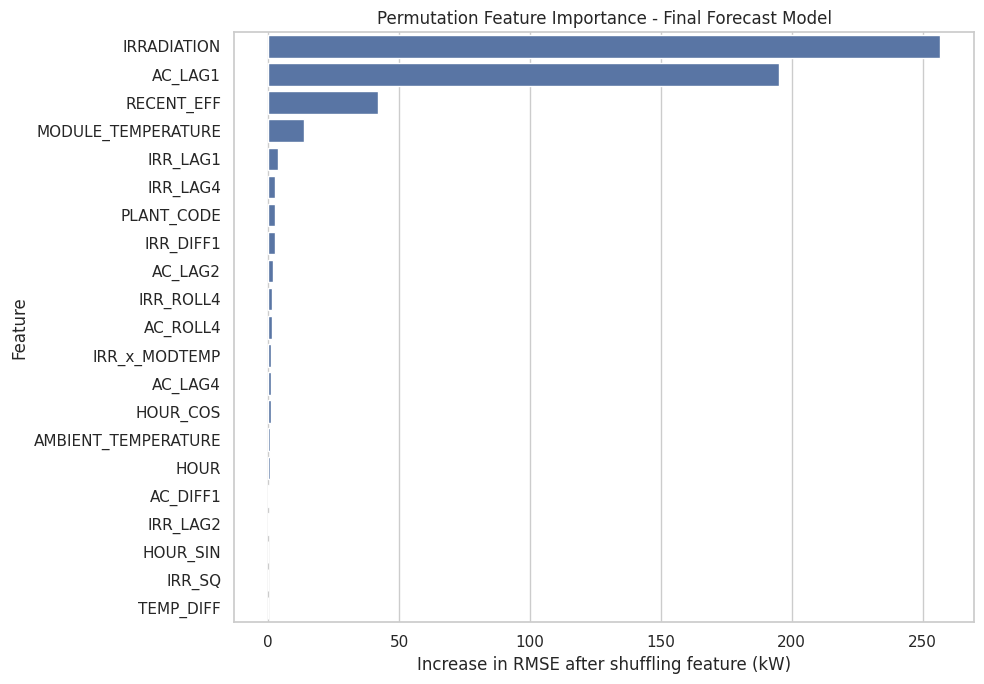

Most important feature: IRRADIATION


In [ ]:
# FEATURE IMPORTANCE OF THE FINAL SELECTED FORECAST MODEL

from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error

# Get the selected Forecast HistGradientBoosting model
final_model = models["Forecast HistGradientBoosting"]

# Use the matching forecast test features
X_importance = Xf_test.copy()
y_importance = y_test.copy()

# Calculate permutation importance using RMSE
def forecast_rmse_scorer(estimator, X, y):
    predictions = physical_post_process(estimator.predict(X), X)
    return -np.sqrt(mean_squared_error(y, predictions))

# Calculate importance on a sample to reduce execution time
perm_forecast = permutation_importance(
    final_model,
    X_importance,
    y_importance,
    scoring=forecast_rmse_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create importance table
forecast_importance = pd.DataFrame({
    "Feature": X_importance.columns,
    "Importance": perm_forecast.importances_mean,
    "Importance_STD": perm_forecast.importances_std
}).sort_values("Importance", ascending=False)

print("FINAL MODEL: FORECAST HISTGRADIENTBOOSTING")
display(forecast_importance)

# Plot feature importance
plt.figure(figsize=(10, 7))
sns.barplot(
    data=forecast_importance,
    x="Importance",
    y="Feature"
)
plt.title("Permutation Feature Importance - Final Forecast Model")
plt.xlabel("Increase in RMSE after shuffling feature (kW)")
plt.ylabel("Feature")
plt.tight_layout()
save_fig("14_final_forecast_feature_importance")

print(
    "Most important feature:",
    forecast_importance.iloc[0]["Feature"]
)

## 4.2 Feature importance explanation
See the three importance charts and the generated explanation in Week 2. In summary: **irradiation** (energy input) and **module temperature** (panel condition) together with the **hour-of-day** encodings (daily sun cycle) drive the predictions; calendar-day features and the plant code add little. This agrees with solar-physics expectations, which increases confidence that the model has learned real relationships rather than noise.

## 4.3 Business insights

SOLAR PLANT PERFORMANCE COMPARISON


,PLANT_ID,Average_AC_Power,Maximum_AC_Power,Average_Irradiation,Average_Module_Temperature,Power_per_Irradiation
0,4135001,307.778375,1410.95,0.232305,31.244997,1324.888958
1,4136001,241.277825,1385.42,0.229204,32.607233,1052.676126


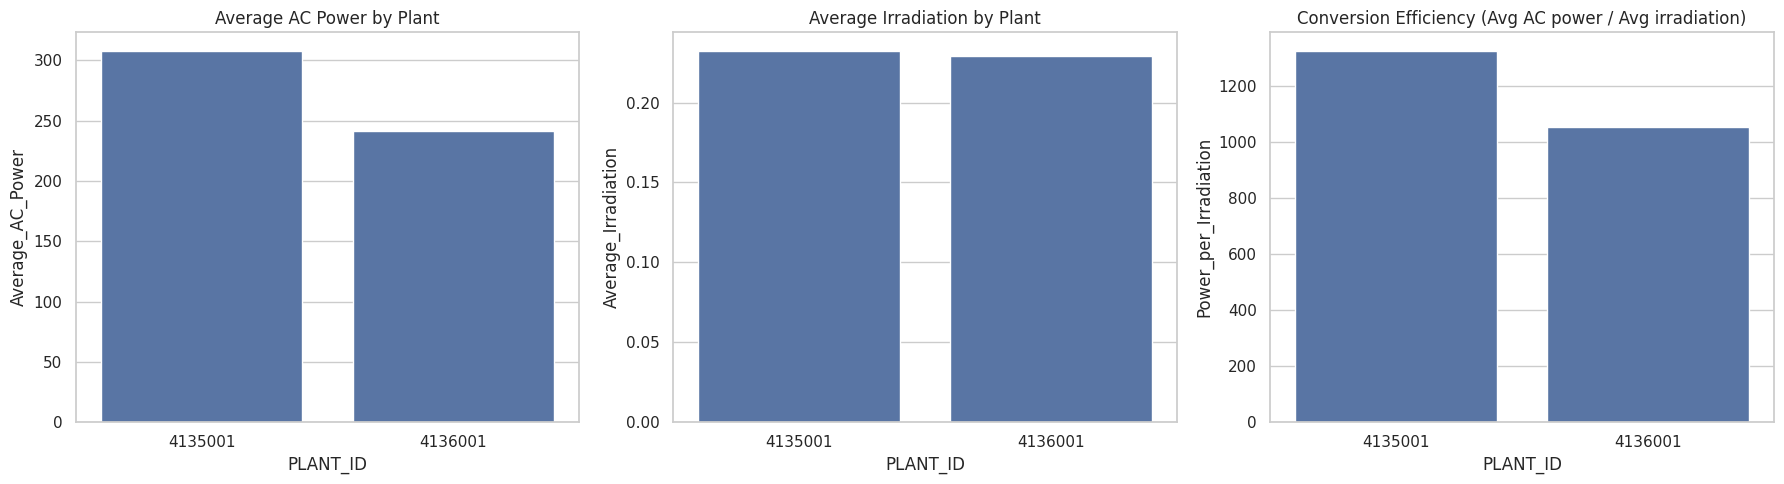

In [ ]:
# PLANT PERFORMANCE COMPARISON
plant_comparison = data.groupby("PLANT_ID").agg(
    Average_AC_Power=("AC_POWER", "mean"),
    Maximum_AC_Power=("AC_POWER", "max"),
    Average_Irradiation=("IRRADIATION", "mean"),
    Average_Module_Temperature=("MODULE_TEMPERATURE", "mean"),
).reset_index()
plant_comparison["Power_per_Irradiation"] = plant_comparison["Average_AC_Power"] / plant_comparison["Average_Irradiation"]

print("SOLAR PLANT PERFORMANCE COMPARISON")
display(plant_comparison)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=plant_comparison, x="PLANT_ID", y="Average_AC_Power", ax=axes[0])
axes[0].set_title("Average AC Power by Plant")
sns.barplot(data=plant_comparison, x="PLANT_ID", y="Average_Irradiation", ax=axes[1])
axes[1].set_title("Average Irradiation by Plant")
sns.barplot(data=plant_comparison, x="PLANT_ID", y="Power_per_Irradiation", ax=axes[2])
axes[2].set_title("Conversion Efficiency (Avg AC power / Avg irradiation)")
save_fig("12_plant_comparison")

INVERTER PERFORMANCE ANALYSIS - most under-performing inverters (actual < predicted)


,PLANT_ID,SOURCE_KEY,Actual_Average,Predicted_Average,Average_Residual,Observations
0,4136001,Quc1TzYxW2pYoWX,146.835071,164.030994,-17.195923,932
1,4136001,Et9kgGMDl729KT4,151.787505,166.763217,-14.975712,932
2,4135001,bvBOhCH3iADSZry,260.173847,272.430905,-12.257058,930
3,4135001,1BY6WEcLGh8j5v7,263.394484,273.882201,-10.487717,930
4,4136001,rrq4fwE8jgrTyWY,186.215183,193.371723,-7.156540,932
5,4136001,LYwnQax7tkwH5Cb,192.301135,196.793399,-4.492264,932
6,4136001,LlT2YUhhzqhg5Sw,197.743210,200.060155,-2.316945,932
7,4136001,9kRcWv60rDACzjR,194.624911,196.707460,-2.082549,932
8,4136001,V94E5Ben1TlhnDV,214.333953,215.988552,-1.654598,932
9,4136001,Qf4GUc1pJu5T6c6,208.024046,208.463370,-0.439324,932


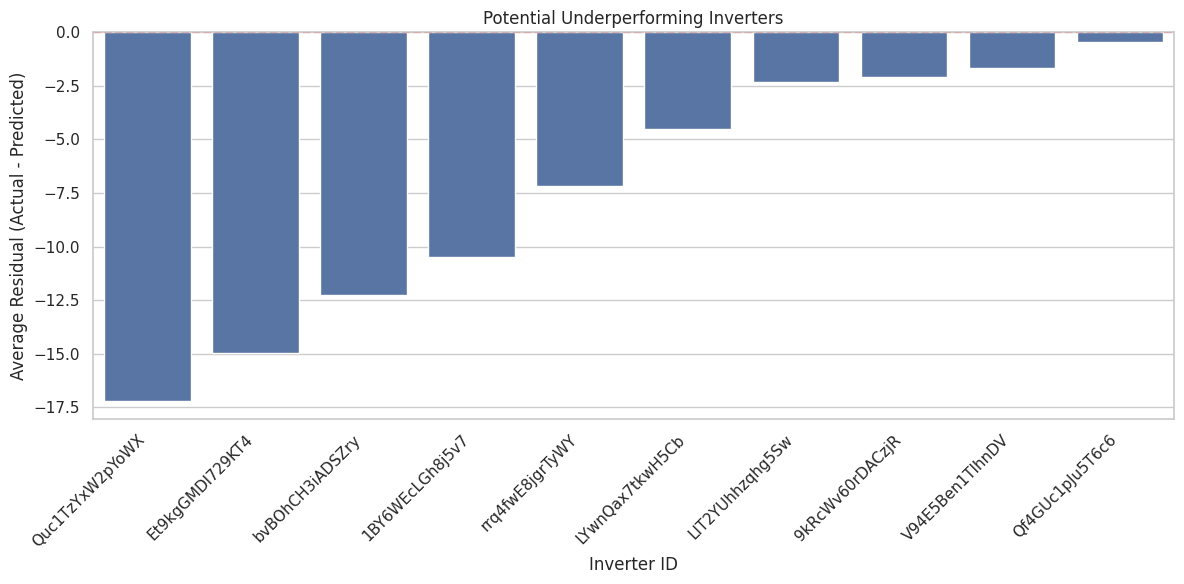

In [ ]:
# INVERTER PERFORMANCE ANALYSIS (test period)
test_data = data.loc[X_test.index].copy()
test_data["PREDICTED_AC_POWER"] = np.asarray(best_predictions)
test_data["RESIDUAL"] = test_data["AC_POWER"] - test_data["PREDICTED_AC_POWER"]

inverter_analysis = test_data.groupby(["PLANT_ID", "SOURCE_KEY"]).agg(
    Actual_Average=("AC_POWER", "mean"),
    Predicted_Average=("PREDICTED_AC_POWER", "mean"),
    Average_Residual=("RESIDUAL", "mean"),
    Observations=("RESIDUAL", "count"),
).reset_index()

inverter_analysis = inverter_analysis[inverter_analysis["Observations"] >= 20]
inverter_analysis = inverter_analysis.sort_values(by="Average_Residual").reset_index(drop=True)

print("INVERTER PERFORMANCE ANALYSIS - most under-performing inverters (actual < predicted)")
display(inverter_analysis.head(10))

plt.figure(figsize=(12, 6))
sns.barplot(data=inverter_analysis.head(10), x="SOURCE_KEY", y="Average_Residual")
plt.axhline(0, color="red", linestyle="--")
plt.title("Potential Underperforming Inverters")
plt.xlabel("Inverter ID")
plt.ylabel("Average Residual (Actual - Predicted)")
plt.xticks(rotation=45, ha="right")
save_fig("13_underperforming_inverters")

In [ ]:
# Auto-generated business insights
best_plant = plant_comparison.sort_values("Average_AC_Power", ascending=False).iloc[0]
eff_plant = plant_comparison.sort_values("Power_per_Irradiation", ascending=False).iloc[0]
worst_inv = inverter_analysis.iloc[0]
n_under = int((inverter_analysis["Average_Residual"] < 0).sum())
shortfall_pct = 100 * abs(worst_inv["Average_Residual"]) / max(worst_inv["Predicted_Average"], 1e-9)

print("BUSINESS INSIGHTS")
print("-" * 70)
say(f"1. Plant {int(best_plant['PLANT_ID'])} generates the highest average AC power per inverter reading ({best_plant['Average_AC_Power']:.1f} kW).")
eff_ratio = plant_comparison["Power_per_Irradiation"].max() / plant_comparison["Power_per_Irradiation"].min()
say(f"2. Plant {int(eff_plant['PLANT_ID'])} converts sunlight into AC power most efficiently "
    f"(average power / average irradiation = {eff_plant['Power_per_Irradiation']:.0f}, {100 * (eff_ratio - 1):.0f}% higher than the other plant). "
    + ("This gap is large enough to suggest equipment, cleaning or inverter issues rather than weather differences." if eff_ratio > 1.1 else "The plants perform similarly."))
say(f"3. Generation peaks around {peak_hour}:00 and is zero at night, so maintenance should be scheduled outside the midday window and storage/dispatch planning should focus on this peak.")
say(f"4. {n_under} of {len(inverter_analysis)} inverters produced on average LESS than the model predicted for their weather. "
    f"The weakest, {worst_inv['SOURCE_KEY']} (Plant {int(worst_inv['PLANT_ID'])}), is about {shortfall_pct:.1f}% below expectation "
    f"({worst_inv['Average_Residual']:.2f} kW on average) and should be inspected first (dirt/soiling, shading, degradation or faults).")
say(f"5. Because the model reaches R2 = {winner['R2 Score']:.3f} with MAE = {winner['MAE']:.2f} kW, short-term forecasts can support real-time dispatch and monitoring "
    f"(day-ahead use needs weather forecasts and the weather-only models), and persistent negative residuals can serve as an automatic early-warning signal for predictive maintenance.")

BUSINESS INSIGHTS
----------------------------------------------------------------------
1. Plant 4135001 generates the highest average AC power per inverter reading (307.8 kW).
2. Plant 4135001 converts sunlight into AC power most efficiently (average power / average irradiation = 1325,
26% higher than the other plant). This gap is large enough to suggest equipment, cleaning or inverter issues
rather than weather differences.
3. Generation peaks around 12:00 and is zero at night, so maintenance should be scheduled outside the midday
window and storage/dispatch planning should focus on this peak.
4. 12 of 44 inverters produced on average LESS than the model predicted for their weather. The weakest,
Quc1TzYxW2pYoWX (Plant 4136001), is about 10.5% below expectation (-17.20 kW on average) and should be
inspected first (dirt/soiling, shading, degradation or faults).
5. Because the model reaches R2 = 0.955 with MAE = 24.02 kW, short-term forecasts can support real-time
dispatch and monitori

## 4.4 Model limitations

1. **Weather dependency:** output depends on sunlight, temperature and cloud cover; sudden weather changes reduce accuracy, and the model needs measured (or forecasted) irradiation as an input.
2. **Short history:** the data cover only **34 days** and **two plants**, so seasonal effects (monsoon, winter) and other climates are not represented; the chronological test period is also very short.
3. **Calendar features:** `DAY`, `MONTH` and `DAY_OF_YEAR` cannot generalise to dates outside the training period (see the feature-set check in Week 2).
4. **Prediction errors:** MAE and RMSE are not zero; the largest errors occur around midday when output is highest, and residuals are heavy-tailed.
5. **Equipment conditions:** dust, shading, degradation and inverter faults are not measured, so the model cannot diagnose their causes; faulty inverters in the training data also teach the model "normal" behaviour that is partly abnormal.
6. **Generalisation:** performance on unseen plants requires additional validation; `PLANT_CODE` only distinguishes the two plants in the data.
7. **Real-time use:** the model is not a pure forecaster - it needs weather inputs for the time being predicted, so deployment requires a weather-forecast feed.

## 4.5 Future improvements

1. Add more plants and a full year of data to learn seasonality and improve generalisation.
2. Integrate real-time weather forecast APIs (irradiation/cloud cover) to turn the model into a true day-ahead forecaster.
3. Add lag/rolling features (previous 15-minute/1-hour power and irradiation) and test LightGBM, CatBoost and LSTM/Temporal models.
4. Use SHAP values for per-prediction explanations.
5. Build an automated inverter anomaly-detection system using persistent negative residuals.
6. Retrain automatically on newly collected data (MLOps pipeline with monitoring for data drift).
7. Quantify forecast uncertainty (prediction intervals / quantile regression).

## 4.6 Deployment insight
**Architecture of a simple production system**

```
 Weather forecast API ─┐
 Plant sensors (IoT) ──┼─►  Feature builder  ─►  Saved model        ─►  Prediction API /      ─►  Dashboard / alerts
 Timestamp & plant id ─┘   (time features,        (solar_model.joblib)    Streamlit app            (operators, grid planners)
                            PLANT_CODE)                 ▲
                                                        │  scheduled retraining on new data + drift monitoring
```

The code below saves the best deployable model and writes a ready-to-run **Streamlit demo** (`app.py`).

In [ ]:
# ---------------------------------------------------------------
# Save the best deployable weather-only model (the simple demo form has no power-history or inverter-efficiency inputs)
# ---------------------------------------------------------------
# The demo form has only the 11 base inputs, so only weather-only models (no lag / inverter-efficiency inputs) can be deployed in it.
deploy_pool = [n for n in cv_rmse if n in results and n in models and not n.startswith(("Boosted", "Forecast"))]
deploy_name = min(deploy_pool, key=lambda n: cv_rmse[n])      # chosen by cross-validation, not by the test set

bundle = {
    "model": models[deploy_name],
    "model_name": deploy_name,
    "features": features,
    "plant_map": plant_map,
    "metrics": {k: float(v) for k, v in results[deploy_name].items() if k != "Model"},
    "ranges": {c: [float(data[c].min()), float(data[c].max())] for c in
               ["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION", "AC_POWER"]},
}
joblib.dump(bundle, "solar_model.joblib")
print("Saved deployable model:", deploy_name, "-> solar_model.joblib (best weather-only model by cross-validation)")

# Sanity check: the reloaded model must reproduce the notebook predictions
reloaded = joblib.load("solar_model.joblib")
check = reloaded["model"].predict(X_test.iloc[:5][reloaded["features"]])
print("Reloaded-model prediction check (first 5 test rows):")
print(np.round(check, 2), "vs", np.round(predictions[deploy_name][:5], 2))
assert np.allclose(check, predictions[deploy_name][:5], atol=1e-3), "Reloaded model does not match!"

Saved deployable model: Tuned XGBoost (GridSearchCV) -> solar_model.joblib (best weather-only model by cross-validation)
Reloaded-model prediction check (first 5 test rows):
[246.74 165.94 246.74 246.74 165.94] vs [246.74 165.94 246.74 246.74 165.94]


In [ ]:
# ---------------------------------------------------------------
# Write the Streamlit demo application (app.py)
# ---------------------------------------------------------------
APP_CODE = r"""
import joblib
import numpy as np
import pandas as pd
import streamlit as st
from datetime import datetime

st.set_page_config(page_title="Solar Power Predictor", page_icon="☀️")

@st.cache_resource
def load_bundle():
    return joblib.load("solar_model.joblib")

bundle = load_bundle()
features = bundle["features"]
plant_map = bundle["plant_map"]
ranges = bundle["ranges"]

st.title("☀️ Solar AC Power Predictor")
st.caption(f"Model: {bundle['model_name']}  |  Test R2: {bundle['metrics']['R2 Score']:.3f}  |  "
           f"Test MAE: {bundle['metrics']['MAE']:.2f} kW")

col1, col2 = st.columns(2)
with col1:
    plant = st.selectbox("Solar plant (PLANT_ID)", list(plant_map.keys()))
    date = st.date_input("Date")
    time = st.time_input("Time")
with col2:
    amb = st.slider("Ambient temperature (°C)", 0.0, 60.0,
                    float(np.clip(25.0, *ranges["AMBIENT_TEMPERATURE"])))
    mod = st.slider("Module temperature (°C)", 0.0, 90.0,
                    float(np.clip(35.0, *ranges["MODULE_TEMPERATURE"])))
    irr = st.slider("Irradiation (kW/m²)", 0.0, 1.6, 0.5, step=0.01)

ts = datetime.combine(date, time)
row = {
    "AMBIENT_TEMPERATURE": amb,
    "MODULE_TEMPERATURE": mod,
    "IRRADIATION": irr,
    "HOUR": ts.hour,
    "DAY": ts.day,
    "MONTH": ts.month,
    "DAY_OF_WEEK": ts.weekday(),
    "DAY_OF_YEAR": ts.timetuple().tm_yday,
    "HOUR_SIN": np.sin(2 * np.pi * ts.hour / 24),
    "HOUR_COS": np.cos(2 * np.pi * ts.hour / 24),
    "PLANT_CODE": plant_map[plant],
}
X_new = pd.DataFrame([row])[features]

if st.button("Predict AC power", type="primary"):
    prediction = max(float(bundle["model"].predict(X_new)[0]), 0.0)
    st.metric("Predicted AC power (kW)", f"{prediction:,.1f}")
    st.dataframe(X_new.T.rename(columns={0: "Input"}))
"""

with open("app.py", "w", encoding="utf-8") as f:
    f.write(APP_CODE.lstrip())

print("app.py written.")
print("\nTo run the demo:")
print("  Local machine : pip install streamlit  &&  streamlit run app.py")
print("  Google Colab  : !pip install -q streamlit && !npm install -g localtunnel")
print("                  !streamlit run app.py &>/dev/null & npx localtunnel --port 8501")

app.py written.

To run the demo:
  Local machine : pip install streamlit  &&  streamlit run app.py
  Google Colab  : !pip install -q streamlit && !npm install -g localtunnel
                  !streamlit run app.py &>/dev/null & npx localtunnel --port 8501


## 4.7 Conclusion
The conclusion below is generated from the executed results, so every number is guaranteed to match the notebook output.

In [ ]:
print("CONCLUSION")
print("=" * 70)
say(f"The Solar Power Prediction project applied machine learning to predict inverter AC power from weather and time information measured at two solar plants. "
    f"After exploratory analysis (missing values, outliers, distributions, correlations), features were encoded and the data was split chronologically 70:30. "
    f"Linear Regression, Decision Tree and KNN were used as baselines, followed by Random Forest, XGBoost (tuned with RandomizedSearchCV and GridSearchCV using time-series cross-validation) "
    f"and an optional neural network.")
print()
say(f"The selected model, {winner['Model']}, achieved R2 = {winner['R2 Score']:.4f} ({winner['R2 Score'] * 100:.2f}%), MAE = {winner['MAE']:.2f} kW and RMSE = {winner['RMSE']:.2f} kW "
    f"on {len(y_test)} unseen test records ({'it is one of the baseline models; the tuned ensembles gave no meaningful improvement' if winner_is_baseline else f'a {improvement:.1f}% RMSE reduction compared with the best baseline'}). "
    f"Feature-importance analysis identified '{imp_xgb.iloc[0]['Feature']}' as the most influential feature, followed by '{imp_xgb.iloc[1]['Feature']}' and '{imp_xgb.iloc[2]['Feature']}'.")
print()
say("Plant-level and inverter-level residual analysis provided practical insights into plant efficiency and potential inverter under-performance, "
    "showing how machine learning can support renewable-energy forecasting, operational monitoring and predictive maintenance. "
    "A saved model and a Streamlit demo (app.py) illustrate deployment.")

CONCLUSION
The Solar Power Prediction project applied machine learning to predict inverter AC power from weather and time
information measured at two solar plants. After exploratory analysis (missing values, outliers, distributions,
correlations), features were encoded and the data was split chronologically 70:30. Linear Regression, Decision
Tree and KNN were used as baselines, followed by Random Forest, XGBoost (tuned with RandomizedSearchCV and
GridSearchCV using time-series cross-validation) and an optional neural network.

The selected model, Forecast HistGradientBoosting, achieved R2 = 0.9555 (95.55%), MAE = 24.02 kW and RMSE =
73.08 kW on 40964 unseen test records (a 47.6% RMSE reduction compared with the best baseline). Feature-
importance analysis identified 'IRRADIATION' as the most influential feature, followed by 'HOUR_COS' and
'MODULE_TEMPERATURE'.

Plant-level and inverter-level residual analysis provided practical insights into plant efficiency and
potential inverter unde